# Soup sprint 1.7B: does a 4.7× bigger model beat the 360M on the same data?

**Main question:** does `SmolLM2-1.7B-Instruct` (≈ 4.7× the parameters) score higher on the general-skill
benchmarks **IFEval** and **HellaSwag** than run 1's 360M (IFEval 31.6, HellaSwag 57.0 after tuning), while still
doing the booking task at least as well? It also reports the booking scores and the cost (speed, adapter size).

| | 360M `ep_3` (run 1, already trained) | 1.7B (this notebook) |
|---|---|---|
| Base model | `SmolLM2-360M-Instruct` | `SmolLM2-1.7B-Instruct` |
| Training data | v1: 2,000 clean rows + 10% replay | **v2: the same 2,000 rows + 1,000 augmented rows** (noise, extra wording) + 10% replay |
| Settings | lr 2e-4, 3 epochs, LoRA r16/α32, seed 42 | 3 epochs, r16/α32, seed 42; **lr 1e-4 or 2e-4, chosen on val** |
| Trainer | fallback (`train_hf.py`) | Soup (no fallback) |

**Read the comparison with care:** the two models differ in **size, training data and trainer**, so a difference
between them is the effect of all three together, not of size alone. The fairest part is the **clean test set**
(v1-style wording, which both models' training covered); on **stress**, the 1.7B also had the benefit of the
augmented rows. The comparison with the **untouched 1.7B** (5.1) is clean.

Both are scored on the v2 evaluation sets (new templates, seed 2027), which neither model has seen.

**Order of work:** generate data → smoke run → two lr runs → choose on **val only** and freeze → test and stress
**once** → paired comparison with `ep_3` and with the untouched 1.7B → cost (speed, adapter size) → IFEval and HellaSwag.

Everything is written to `MyDrive/soup-sprint-1p7b/`; run 1's folder `MyDrive/soup-sprint/` is only read
(for its `ep_3` adapter, its replay file and its data checksum).

| Phase | What | GPU time | Checks |
|---|---|---|---|
| 0 | Setup | — | 0.1–0.3 |
| 1 | Generate v2 data, `ep_3` predictions | ~5 min | 1.1–1.6, 1.H, 1.V, 1.C |
| 2 | Baseline: untouched 1.7B on val | ~2 min | 2.1 |
| 3 | Smoke run (200 rows, 1 epoch) | ~3 min | 3.1–3.3 |
| 4 | lr 1e-4 and 2e-4, choose on val, freeze | ~60–80 min | 4.1–4.4 |
| 5 | Test + stress once; vs 360M and vs 1.7B base | ~5 min | 5.1–5.7 |
| 6 | **General skills (IFEval, HellaSwag): the main result** | ~60–90 min | 6.1–6.3 |
| 7 | Results summary | — | — |

## Phase 0 — Setup (≈ 10 min)

Use an **A100** (40 or 80 GB) with High-RAM. A 1.7B model with LoRA in bf16 needs about 4 GB of weights plus
activations, so batch 16 fits comfortably; an L4 (24 GB) also works, about 2× slower.

| # | Check | Pass when |
|---|---|---|
| 0.1 | GPU | A GPU is visible, supports bf16, and has ≥ 20 GB of memory |
| 0.2 | Soup | `soup --version` and `soup doctor` exit 0 |
| 0.3 | Drive | `MyDrive/soup-sprint-1p7b/` exists and `reports/pip_freeze.txt` was written |

In [1]:
!nvidia-smi
import sys; print("python", sys.version)

Wed Nov 11 19:38:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   33C    P0             55W /  400W |       0MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [2]:
import os
from google.colab import drive
drive.mount("/content/drive")

PROJECT = "/content/drive/MyDrive/soup-sprint-1p7b"
V1_PROJECT = "/content/drive/MyDrive/soup-sprint"      # run 1: read only
for d in ["scripts", "tests", "data/eval", "data_v1", "configs", "runs", "reports/preds", "logs"]:
    os.makedirs(os.path.join(PROJECT, d), exist_ok=True)
os.chdir(PROJECT)
print("working in", os.getcwd(), "| run 1 folder found:", os.path.isdir(V1_PROJECT))

Mounted at /content/drive
working in /content/drive/MyDrive/soup-sprint-1p7b | run 1 folder found: True


In [3]:
# ~2-4 min
!pip -q install "soup-cli[train,eval]" pyyaml pytest tabulate
# Colab preinstalls torchao 0.10, which recent peft refuses to load (needs > 0.16). Neither Soup nor this project uses it.
!pip uninstall -y -q torchao
!soup --version

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
soup v0.77.2
https://github.com/MakazhanAlpamys/Soup


### Write the project files to Drive

In [4]:
%%writefile scripts/common.py
"""Shared task definition: fields, rules, schema and prompt format."""
from __future__ import annotations

import datetime as dt
import re

INTENTS = ["book", "reschedule", "cancel", "check"]
FIELDS = ["intent", "date", "time", "resource", "needs_clarification"]
REQUIRED = {
    "book": ["date", "time", "resource"],
    "reschedule": ["date", "time"],
    "cancel": ["date"],
    "check": ["date", "resource"],
}
RESOURCES = ["Room A", "Room B", "Room C", "Studio 1", "Studio 2", "Lab 3", "Court 1", "Court 2"]

_DATE_RE = re.compile(r"^\d{4}-\d{2}-\d{2}$")
_TIME_RE = re.compile(r"^([01]\d|2[0-3]):[0-5]\d$")

INSTRUCTION = (
    "Extract the booking request below as JSON. Reply with only a JSON object with exactly these keys: "
    '"intent" (one of "book", "reschedule", "cancel", "check"), '
    '"date" ("YYYY-MM-DD" or null), "time" ("HH:MM", 24-hour, or null), '
    '"resource" (room or facility name, or null), '
    '"needs_clarification" (true if a value the intent needs is missing, else false). '
    "Use null for anything the request does not state."
)


def needs_clarification(rec: dict) -> bool:
    return any(rec.get(f) is None for f in REQUIRED[rec["intent"]])


def build_prompt(request: str, today: dt.date) -> str:
    return f"{INSTRUCTION}\nToday is {today.strftime('%A')}, {today.isoformat()}.\nRequest: {request}"


def label_to_text(label: dict) -> str:
    import json
    return json.dumps({k: label[k] for k in FIELDS}, ensure_ascii=False)


def schema_errors(obj) -> list[str]:
    """Return a list of problems; empty list means schema-valid."""
    errs: list[str] = []
    if not isinstance(obj, dict):
        return ["not_an_object"]
    keys = set(obj)
    if keys != set(FIELDS):
        missing = set(FIELDS) - keys
        extra = keys - set(FIELDS)
        if missing:
            errs.append(f"missing_keys:{sorted(missing)}")
        if extra:
            errs.append(f"extra_keys:{sorted(extra)}")
    if "intent" in obj and obj["intent"] not in INTENTS:
        errs.append("bad_intent")
    if "date" in obj and obj["date"] is not None:
        d = obj["date"]
        ok = isinstance(d, str) and bool(_DATE_RE.match(d))
        if ok:
            try:
                dt.date.fromisoformat(d)
            except ValueError:
                ok = False
        if not ok:
            errs.append("bad_date")
    if "time" in obj and obj["time"] is not None:
        t = obj["time"]
        if not (isinstance(t, str) and _TIME_RE.match(t)):
            errs.append("bad_time")
    if "resource" in obj and obj["resource"] is not None:
        r = obj["resource"]
        if not (isinstance(r, str) and r.strip()):
            errs.append("bad_resource")
    if "needs_clarification" in obj and not isinstance(obj["needs_clarification"], bool):
        errs.append("bad_needs_clarification")
    return errs


def label_errors(label: dict) -> list[str]:
    """Schema check plus the consistency rule, used on generated gold labels."""
    errs = schema_errors(label)
    if not errs and label["needs_clarification"] != needs_clarification(label):
        errs.append("inconsistent_needs_clarification")
    if not errs and label["resource"] is not None and label["resource"] not in RESOURCES:
        errs.append("unknown_resource")
    return errs

Overwriting scripts/common.py


In [5]:
%%writefile scripts/generate_data.py
"""Generate train / val / test / stress splits with rule-computed labels.

Splits are separated by template family: every split uses its own sentence templates.
Usage: python scripts/generate_data.py --out data --seed 1234
"""
from __future__ import annotations

import argparse
import datetime as dt
import hashlib
import json
import os
import random
import re
import sys

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from common import FIELDS, INTENTS, REQUIRED, RESOURCES, build_prompt, label_to_text, needs_clarification  # noqa: E402

# ---------------------------------------------------------------- templates
# "[ ... {slot} ...]" is an optional segment, dropped when the slot is missing.
# Date surfaces include their own preposition ("on December 7", "tomorrow"); time surfaces include "at".
TEMPLATES = {
    "train": {
        "book": [
            "Please book[ {resource}][ {date}][ {time}].",
            "I'd like to reserve[ {resource}][ {date}][ {time}].",
            "Can you get me[ {resource}][ {date}][ {time}]?",
            "Book[ {resource}] for me[ {date}][ {time}] please.",
            "I need a booking[ for {resource}][ {date}][ {time}], can you set that up?",
            "Reserve[ {resource}][ {time}][ {date}] for our team.",
        ],
        "reschedule": [
            "Please move my booking[ for {resource}][ to {date}][ {time}].",
            "Can I change my reservation[ of {resource}][ to {date}][ {time}]?",
            "Reschedule my[ {resource}] slot[ to {date}][ {time}].",
            "I need to shift my appointment[ in {resource}][ to {date}][ {time}].",
            "Push my booking[ for {resource}] back[ to {date}][ {time}].",
            "Could we move it[ to {date}][ {time}] instead?[ It's the {resource} booking.]",
        ],
        "cancel": [
            "Please cancel my booking[ for {resource}][ {date}][ {time}].",
            "Cancel the[ {resource}] reservation[ {date}][ {time}].",
            "I won't need my booking[ of {resource}][ {date}][ {time}] anymore, please cancel it.",
            "Drop my reservation[ {date}][ {time}][ for {resource}].",
            "Can you call off my booking[ in {resource}][ {date}][ {time}]?",
            "Remove my[ {resource}] slot[ {date}][ {time}] from the calendar.",
        ],
        "check": [
            "Is there availability[ in {resource}][ {date}][ {time}]?",
            "Can you check availability[ for {resource}][ {date}][ {time}]?",
            "Do you have any openings[ in {resource}][ {date}][ {time}]?",
            "What's the availability[ of {resource}][ {date}][ {time}]?",
            "Any free slots[ for {resource}][ {date}][ {time}]?",
            "I want to know whether there is space[ in {resource}][ {date}][ {time}].",
        ],
    },
    "val": {
        "book": [
            "Could I grab a slot[ in {resource}][ {date}][ {time}]?",
            "Hold[ {resource}] for us[ {date}][ {time}].",
        ],
        "reschedule": [
            "Something came up, can we do[ {date}][ {time}] instead for my[ {resource}] reservation?",
            "Let's change the time of my booking[ in {resource}][ to {date}][ {time}].",
        ],
        "cancel": [
            "We no longer need the booking[ for {resource}][ {date}][ {time}], scrap it.",
            "Kindly delete my reservation[ of {resource}][ {date}][ {time}].",
        ],
        "check": [
            "Would there be room[ in {resource}][ {date}][ {time}]?",
            "Look up if anything is open[ in {resource}][ {date}][ {time}].",
        ],
    },
    "test": {
        "book": [
            "We would like a reservation[ for {resource}][ {date}][ {time}] please.",
            "Set up a booking[ for {resource}][ {date}][ {time}] if possible.",
        ],
        "reschedule": [
            "Is it possible to postpone my[ {resource}] booking[ until {date}][ {time}]?",
            "I'd prefer[ {date}][ {time}] for my[ {resource}] reservation instead of the current one.",
        ],
        "cancel": [
            "Our plans changed so please release the[ {resource}] booking[ {date}][ {time}].",
            "Forget about my reservation[ for {resource}][ {date}][ {time}], it's cancelled.",
        ],
        "check": [
            "Is there a vacancy[ for {resource}][ {date}][ {time}]?",
            "Please find out if a spot is available[ in {resource}][ {date}][ {time}].",
        ],
    },
}
TEMPLATES["stress"] = TEMPLATES["test"]  # same families as test, plus noise and unseen wording

SPLIT_CFG = {  # rows, probability that >=1 required field is missing, use unseen surface forms
    "train": dict(n=2000, p_missing=0.28, stress=False),
    "val": dict(n=300, p_missing=0.30, stress=False),
    "test": dict(n=300, p_missing=0.50, stress=False),
    "stress": dict(n=150, p_missing=0.50, stress=True),
}

MONTHS = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
NUM_WORDS = {1: "one", 2: "two", 3: "three", 4: "four", 5: "five", 6: "six", 7: "seven", 8: "eight",
             9: "nine", 10: "ten", 11: "eleven", 12: "twelve"}


def ordinal(n: int) -> str:
    suf = "th" if 10 <= n % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(n % 10, "th")
    return f"{n}{suf}"


# ---------------------------------------------------------------- date rules
def next_weekday(today: dt.date, weekday: int) -> dt.date:
    """Rule: 'next <Weekday>' = the first such day strictly after today."""
    delta = (weekday - today.weekday()) % 7
    return today + dt.timedelta(days=delta or 7)


def date_surface(today: dt.date, rng: random.Random, stress: bool) -> tuple[str, str]:
    base_forms = ["today", "tomorrow", "day_after", "in_n_days", "next_weekday",
                  "month_day", "day_month", "iso", "ordinal_of"]
    stress_forms = ["week_from_today", "two_weeks", "in_n_days_words", "abbr_dot", "day_abbr"]
    form = rng.choice(stress_forms if (stress and rng.random() < 0.7) else base_forms)
    if form == "today":
        return "today", today.isoformat()
    if form == "tomorrow":
        return "tomorrow", (today + dt.timedelta(days=1)).isoformat()
    if form == "day_after":
        return "the day after tomorrow", (today + dt.timedelta(days=2)).isoformat()
    if form == "in_n_days":
        n = rng.randint(2, 14)
        return f"in {n} days", (today + dt.timedelta(days=n)).isoformat()
    if form == "next_weekday":
        w = rng.randrange(7)
        return f"next {WEEKDAYS[w]}", next_weekday(today, w).isoformat()
    if form == "week_from_today":
        return "a week from today", (today + dt.timedelta(days=7)).isoformat()
    if form == "two_weeks":
        return "two weeks from today", (today + dt.timedelta(days=14)).isoformat()
    if form == "in_n_days_words":
        n = rng.randint(2, 10)
        return f"in {NUM_WORDS[n]} days", (today + dt.timedelta(days=n)).isoformat()
    # absolute dates: always within the next 1..90 days, so "December 7" has one meaning
    target = today + dt.timedelta(days=rng.randint(1, 90))
    m, d = MONTHS[target.month - 1], target.day
    surface = {
        "month_day": f"on {m} {d}",
        "day_month": f"on {d} {m}",
        "iso": f"on {target.isoformat()}",
        "ordinal_of": f"on the {ordinal(d)} of {m}",
        "abbr_dot": f"on {m[:3]}. {ordinal(d)}",
        "day_abbr": f"on {ordinal(d)} {m[:3]}",
    }[form]
    return surface, target.isoformat()


# ---------------------------------------------------------------- time rules
def _h12(h: int) -> tuple[int, str]:
    return (h % 12 or 12), ("am" if h < 12 else "pm")


def _part_of_day(h: int) -> str:
    return "in the morning" if h < 12 else ("in the afternoon" if h < 17 else "in the evening")


def time_surface(rng: random.Random, stress: bool) -> tuple[str, str]:
    h = rng.randint(7, 21)
    m = rng.choice([0, 0, 0, 30, 30, 15, 45])
    iso = f"{h:02d}:{m:02d}"
    h12, ap = _h12(h)
    base = ["h24", "ampm", "ampm_space", "oclock", "noon"]
    strs = ["half_past", "quarter", "military", "dotted", "midday"]
    order = (strs if (stress and rng.random() < 0.7) else base)[:]
    rng.shuffle(order)
    for form in order + ["h24"]:
        if form == "h24":
            return f"at {iso}", iso
        if form == "ampm":
            return (f"at {h12}{ap}" if m == 0 else f"at {h12}:{m:02d}{ap}"), iso
        if form == "ampm_space":
            return (f"at {h12} {ap}" if m == 0 else f"at {h12}:{m:02d} {ap}"), iso
        if form == "oclock" and m == 0:
            return f"at {h12} o'clock {_part_of_day(h)}", iso
        if form == "noon" and h == 12 and m == 0:
            return "at noon", iso
        if form == "midday" and h == 12 and m == 0:
            return "at midday", iso
        if form == "half_past" and m == 30:
            return f"at half past {NUM_WORDS[h12]} {_part_of_day(h)}", iso
        if form == "quarter" and m == 15:
            return f"at quarter past {NUM_WORDS[h12]} {_part_of_day(h)}", iso
        if form == "quarter" and m == 45:
            nh12, _ = _h12(h + 1)
            return f"at quarter to {NUM_WORDS[nh12]} {_part_of_day(h + 1)}", iso
        if form == "military":
            return f"at {h:02d}{m:02d}h", iso
        if form == "dotted":
            return f"at {h12}.{m:02d} {'a.m.' if ap == 'am' else 'p.m.'}", iso
    raise AssertionError("unreachable")


# ---------------------------------------------------------------- resource rules
def resource_surface(rng: random.Random, stress: bool) -> tuple[str, str]:
    res = rng.choice(RESOURCES)
    kind, ident = res.split(" ")
    if stress and rng.random() < 0.7:
        word = NUM_WORDS[int(ident)] if ident.isdigit() else ident
        forms = {
            "Room": [f"rm {ident}", f"room-{ident}"],
            "Studio": [f"studio {word}", f"studio no. {ident}"],
            "Lab": [f"laboratory {ident}", f"lab no. {ident}"],
            "Court": [f"court no. {ident}", f"court {word}"],
        }[kind]
        return rng.choice(forms), res
    return rng.choice([res, res, f"{kind.lower()} {ident}"]), res


# ---------------------------------------------------------------- rendering
_SEG_RE = re.compile(r"\[([^\]]*)\]")
_SLOT_RE = re.compile(r"\{(\w+)\}")


def render(template: str, surfaces: dict) -> list[tuple[str, bool]]:
    """Render to segments [(text, is_slot)]. Missing slots drop their optional segment."""
    pieces: list[tuple[str, bool]] = []
    pos = 0
    for m in _SEG_RE.finditer(template):
        pieces.extend(_render_plain(template[pos:m.start()], surfaces))
        inner = m.group(1)
        slots = _SLOT_RE.findall(inner)
        if all(surfaces.get(s) is not None for s in slots):
            pieces.extend(_render_plain(inner, surfaces))
        pos = m.end()
    pieces.extend(_render_plain(template[pos:], surfaces))
    return pieces


def _render_plain(text: str, surfaces: dict) -> list[tuple[str, bool]]:
    out, pos = [], 0
    for m in _SLOT_RE.finditer(text):
        out.append((text[pos:m.start()], False))
        out.append((surfaces[m.group(1)], True))
        pos = m.end()
    out.append((text[pos:], False))
    return [p for p in out if p[0]]


def clean(text: str) -> str:
    text = re.sub(r"\s+", " ", text).strip()
    text = re.sub(r"\s+([.,?!])", r"\1", text)
    # "to on December 7" -> "to December 7";  "to in 3 days" -> "in 3 days"
    text = re.sub(r"\b(to|until) on\b", r"\1", text, flags=re.I)
    text = re.sub(r"\b(?:to|until) (in \w+ days)\b", r"\1", text, flags=re.I)
    return text[0].upper() + text[1:] if text else text


# ---------------------------------------------------------------- noise (stress only)
FILLERS_PRE = ["hey,", "hi there!", "um so", "hello,", "ok so", "quick one:"]
FILLERS_POST = ["thanks!", "cheers", "asap pls", "thank you so much", "ty"]


def _typo(word: str, rng: random.Random) -> str:
    if len(word) < 4 or not word.isalpha():
        return word
    i = rng.randrange(len(word) - 1)
    op = rng.choice(["swap", "drop", "double"])
    if op == "swap":
        return word[:i] + word[i + 1] + word[i] + word[i + 2:]
    if op == "drop":
        return word[:i] + word[i + 1:]
    return word[:i] + word[i] + word[i:]


def add_noise(segments: list[tuple[str, bool]], rng: random.Random) -> str:
    segs = [list(s) for s in segments]
    if rng.random() < 0.5:  # 1-2 typos, only in template words (never inside a slot value)
        cand = [(i, j) for i, (t, slot) in enumerate(segs) if not slot
                for j, w in enumerate(t.split(" ")) if len(w) >= 4 and w.isalpha()]
        for i, j in rng.sample(cand, k=min(len(cand), rng.randint(1, 2))):
            words = segs[i][0].split(" ")
            words[j] = _typo(words[j], rng)
            segs[i][0] = " ".join(words)
    text = clean("".join(t for t, _ in segs))
    if rng.random() < 0.4:
        text = f"{rng.choice(FILLERS_PRE)} {text[0].lower()}{text[1:]}"
    if rng.random() < 0.4:
        text = f"{text} {rng.choice(FILLERS_POST)}"
    r = rng.random()
    if r < 0.15:
        text = text.upper()
    elif r < 0.35:
        text = text.lower()
    return text


# ---------------------------------------------------------------- sampling
def sample_presence(intent: str, p_missing: float, rng: random.Random) -> dict:
    req = REQUIRED[intent]
    present = {f: True for f in ["date", "time", "resource"]}
    for f in ["date", "time", "resource"]:
        if f not in req:
            present[f] = rng.random() < 0.5  # optional fields: 50/50
    if rng.random() < p_missing:
        k = 1 if (len(req) == 1 or rng.random() < 0.75) else rng.randint(2, len(req))
        for f in rng.sample(req, k):
            present[f] = False
    return present


def make_row(split: str, rng: random.Random, start: dt.date) -> dict:
    cfg = SPLIT_CFG[split]
    intent = rng.choice(INTENTS)
    t_idx = rng.randrange(len(TEMPLATES[split][intent]))
    template = TEMPLATES[split][intent][t_idx]
    today = start + dt.timedelta(days=rng.randrange(730))
    present = sample_presence(intent, cfg["p_missing"], rng)
    label = {"intent": intent, "date": None, "time": None, "resource": None}
    surfaces = {}
    if present["date"]:
        surfaces["date"], label["date"] = date_surface(today, rng, cfg["stress"])
    if present["time"]:
        surfaces["time"], label["time"] = time_surface(rng, cfg["stress"])
    if present["resource"]:
        surfaces["resource"], label["resource"] = resource_surface(rng, cfg["stress"])
    label["needs_clarification"] = needs_clarification(label)
    segments = render(template, surfaces)
    request = add_noise(segments, rng) if cfg["stress"] else clean("".join(t for t, _ in segments))
    family = f"{'test' if split == 'stress' else split}/{intent}/{t_idx}"
    return {
        "split": split, "template": family, "today": today.isoformat(), "request": request,
        "prompt": build_prompt(request, today), "label": {k: label[k] for k in FIELDS},
    }


def generate(seed: int = 1234) -> dict[str, list[dict]]:
    rng = random.Random(seed)
    start = dt.date(2026, 1, 1)
    seen: set[str] = set()
    out: dict[str, list[dict]] = {}
    for split in ["train", "val", "test", "stress"]:
        rows, tries = [], 0
        while len(rows) < SPLIT_CFG[split]["n"]:
            tries += 1
            if tries > 200_000:
                raise RuntimeError(f"could not generate enough unique rows for {split}")
            row = make_row(split, rng, start)
            key = re.sub(r"\W+", " ", row["request"].lower()).strip()
            if key in seen:  # no request text is shared across (or within) splits
                continue
            seen.add(key)
            row["id"] = f"{split}-{len(rows):04d}"
            rows.append(row)
        out[split] = rows
    return out


def sha256(path: str) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 16), b""):
            h.update(chunk)
    return h.hexdigest()


def write_jsonl(path: str, rows: list[dict]) -> None:
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--out", default="data")
    ap.add_argument("--seed", type=int, default=1234)
    args = ap.parse_args()
    splits = generate(args.seed)
    # train.jsonl holds only chat messages (what Soup trains on); metadata goes to a sidecar file
    train_chat = [{"messages": [{"role": "user", "content": r["prompt"]},
                                {"role": "assistant", "content": label_to_text(r["label"])}]}
                  for r in splits["train"]]
    files = {
        "train.jsonl": train_chat,
        "train_meta.jsonl": splits["train"],
        "eval/val.jsonl": splits["val"],
        "eval/test.jsonl": splits["test"],
        "eval/stress.jsonl": splits["stress"],
    }
    for rel, rows in files.items():
        write_jsonl(os.path.join(args.out, rel), rows)
    manifest = {"seed": args.seed,
                "files": {rel: {"rows": len(rows), "sha256": sha256(os.path.join(args.out, rel))}
                          for rel, rows in files.items()}}
    with open(os.path.join(args.out, "manifest.json"), "w") as f:
        json.dump(manifest, f, indent=2)
    for rel, info in manifest["files"].items():
        print(f"{rel:22s} {info['rows']:5d} rows  sha256={info['sha256'][:12]}…")


if __name__ == "__main__":
    main()

Overwriting scripts/generate_data.py


In [6]:
%%writefile scripts/generate_data_v2.py
"""Generate the v2 data: v1 training rows + noisy, more varied training rows, and NEW val/test/stress sets.

What changed from v1:
- train = the 2,000 v1 training rows, unchanged, + 1,000 augmented rows (noise and extra wordings).
- Wording comes in three tiers. "base" = v1 wording. "extra" = new wording that training sees.
  "heldout" = wording that only the stress set uses, so stress still measures generalisation.
- Noise also has a training style and a stress style: the stress fillers are different and stress adds a
  keyboard-neighbour typo that training never sees.
- test and stress use 8 NEW template families. v1's test templates have been looked at, so they move into training.
- Every row records what was done to it (`group`, `noise`, `forms`), so stress can be scored per group:
  noise_only, new_wording, both.

Usage: python scripts/generate_data_v2.py --out data --seed 2027 --v1-seed 1234
"""
from __future__ import annotations

import argparse
import datetime as dt
import json
import os
import random
import re
import sys

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import generate_data as v1  # noqa: E402
from common import FIELDS, INTENTS, build_prompt, label_to_text, needs_clarification  # noqa: E402
from generate_data import MONTHS, NUM_WORDS, WEEKDAYS, next_weekday, ordinal, render  # noqa: E402


def clean(text: str) -> str:
    """v1 clean(), plus: a sentence ending in "a.m." / "p.m." keeps a single period ("10.30 a.m.." -> "10.30 a.m.")."""
    return re.sub(r"(\s[ap])\.m\.\.", r"\1.m.", v1.clean(text))

# ---------------------------------------------------------------- templates
# 8 new families, used only by test and stress. Nobody has seen rows from them.
NEW_TEST_TEMPLATES = {
    "book": [
        "Could you pencil me in[ for {resource}][ {date}][ {time}]?",
        "Put me down for a slot[ in {resource}][ {date}][ {time}].",
    ],
    "reschedule": [
        "My[ {resource}] booking needs to be moved[ to {date}][ {time}].",
        "Can my[ {resource}] reservation be switched[ to {date}][ {time}]?",
    ],
    "cancel": [
        "Take my[ {resource}] booking[ {date}][ {time}] off the schedule, we can't make it.",
        "I have to withdraw my reservation[ for {resource}][ {date}][ {time}].",
    ],
    "check": [
        "Tell me whether anything is free[ in {resource}][ {date}][ {time}].",
        "Can you see if there's an opening[ in {resource}][ {date}][ {time}]?",
    ],
}
# augmented training rows use v1's train templates + v1's (retired) test templates
TRAIN_AUG_TEMPLATES = {i: v1.TEMPLATES["train"][i] + v1.TEMPLATES["test"][i] for i in INTENTS}
N_V1_TRAIN = {i: len(v1.TEMPLATES["train"][i]) for i in INTENTS}

SPLIT_CFG = {
    "train_aug": dict(n=1000, p_missing=0.28),
    "val": dict(n=300, p_missing=0.30),
    "test": dict(n=300, p_missing=0.50),
    "stress": dict(n=300, p_missing=0.50),
}

# ---------------------------------------------------------------- wording tiers
DATE_FORMS = {
    "base": ["today", "tomorrow", "day_after", "in_n_days", "next_weekday", "month_day", "day_month", "iso", "ordinal_of"],
    "extra": ["week_from_today", "in_n_days_words", "abbr_dot", "month_day_ordinal"],
    "heldout": ["two_weeks", "days_from_now", "day_abbr", "abbr_nodot", "tmrw"],
}
TIME_FORMS = {
    "base": ["h24", "ampm", "ampm_space", "oclock", "noon"],
    "extra": ["half_past", "quarter", "dotted", "midday"],
    "heldout": ["military", "h12_part", "ampm_caps", "h_h"],
}
RESOURCE_FORMS = {
    "base": ["canonical", "lower_kind"],
    "extra": ["short", "hyphen", "word", "long"],
    "heldout": ["nospace", "hash", "number_spelled", "conference"],
}
TIERS = ["base", "extra", "heldout"]


def date_text(today: dt.date, form: str, rng: random.Random) -> tuple[str, str]:
    rel = {"today": ("today", 0), "tomorrow": ("tomorrow", 1), "day_after": ("the day after tomorrow", 2),
           "week_from_today": ("a week from today", 7), "two_weeks": ("two weeks from today", 14), "tmrw": ("tmrw", 1)}
    if form in rel:
        text, n = rel[form]
        return text, (today + dt.timedelta(days=n)).isoformat()
    if form in ("in_n_days", "in_n_days_words", "days_from_now"):
        n = rng.randint(2, 10 if form == "in_n_days_words" else 14)
        text = (f"in {NUM_WORDS[n]} days" if form == "in_n_days_words"
                else f"{n} days from now" if form == "days_from_now" else f"in {n} days")
        return text, (today + dt.timedelta(days=n)).isoformat()
    if form == "next_weekday":
        w = rng.randrange(7)
        return f"next {WEEKDAYS[w]}", next_weekday(today, w).isoformat()
    # absolute dates: always within the next 1..90 days, so "December 7" has one meaning
    target = today + dt.timedelta(days=rng.randint(1, 90))
    m, d = MONTHS[target.month - 1], target.day
    text = {
        "month_day": f"on {m} {d}",
        "day_month": f"on {d} {m}",
        "iso": f"on {target.isoformat()}",
        "ordinal_of": f"on the {ordinal(d)} of {m}",
        "month_day_ordinal": f"on {m} {ordinal(d)}",
        "abbr_dot": f"on {m[:3]}. {ordinal(d)}",
        "day_abbr": f"on {ordinal(d)} {m[:3]}",
        "abbr_nodot": f"on {m[:3]} {d}",
    }[form]
    return text, target.isoformat()


def _h12(h: int) -> tuple[int, str]:
    return (h % 12 or 12), ("am" if h < 12 else "pm")


def _part_of_day(h: int) -> str:
    return "in the morning" if h < 12 else ("in the afternoon" if h < 17 else "in the evening")


def time_text(h: int, m: int, form: str) -> str | None:
    """Surface text for h:m in `form`, or None when the form does not apply to this time."""
    h12, ap = _h12(h)
    hm12 = f"{h12}" if m == 0 else f"{h12}:{m:02d}"
    part = _part_of_day(h)  # always the part of day of the actual time (11:45 is "in the morning")
    if form == "h24":
        return f"at {h:02d}:{m:02d}"
    if form == "ampm":
        return f"at {hm12}{ap}"
    if form == "ampm_space":
        return f"at {hm12} {ap}"
    if form == "oclock":
        return f"at {h12} o'clock {part}" if m == 0 else None
    if form in ("noon", "midday"):
        return f"at {form}" if (h, m) == (12, 0) else None
    if form == "half_past":
        return f"at half past {NUM_WORDS[h12]} {part}" if m == 30 else None
    if form == "quarter":
        if m == 15:
            return f"at quarter past {NUM_WORDS[h12]} {part}"
        if m == 45:
            return f"at quarter to {NUM_WORDS[_h12(h + 1)[0]]} {part}"
        return None
    if form == "dotted":
        return f"at {h12}.{m:02d} {'a.m.' if ap == 'am' else 'p.m.'}"
    if form == "military":
        return f"at {h:02d}{m:02d}h"
    if form == "h12_part":
        return f"at {hm12} {part}"
    if form == "ampm_caps":
        return f"at {hm12}{ap.upper()}"
    if form == "h_h":
        return f"at {h}h{m:02d}"
    raise ValueError(form)


def resource_text(res: str, form: str) -> str | None:
    """Surface text for a canonical resource ("Studio 2") in `form`, or None when it does not apply."""
    kind, ident = res.split(" ")
    low = kind.lower()
    word = NUM_WORDS[int(ident)] if ident.isdigit() else None
    if form == "canonical":
        return res
    if form == "lower_kind":
        return f"{low} {ident}"
    if form == "short":
        return f"rm {ident}" if kind == "Room" else f"{low} no. {ident}"
    if form == "hyphen":
        return f"{low}-{ident}"
    if form == "word":
        return f"{low} {word}" if word else None
    if form == "long":
        return f"laboratory {ident}" if kind == "Lab" else None
    if form == "nospace":
        return f"{low}{ident}"
    if form == "hash":
        return f"{low} #{ident}"
    if form == "number_spelled":
        return f"{low} number {word}" if word else None
    if form == "conference":
        return f"conference room {ident}" if kind == "Room" else None
    raise ValueError(form)


def pick_date(today, tier, rng):
    form = rng.choice(DATE_FORMS[tier])
    text, iso = date_text(today, form, rng)
    return text, iso, form


def pick_time(tier, rng):
    h, m = rng.randint(7, 21), rng.choice([0, 0, 0, 30, 30, 15, 45])
    for form in rng.sample(TIME_FORMS[tier], len(TIME_FORMS[tier])):
        text = time_text(h, m, form)
        if text:
            return text, f"{h:02d}:{m:02d}", form
    raise AssertionError("every tier has a form that always applies")


def pick_resource(tier, rng):
    res = rng.choice(v1.RESOURCES)
    for form in rng.sample(RESOURCE_FORMS[tier], len(RESOURCE_FORMS[tier])):
        text = resource_text(res, form)
        if text:
            return text, res, form
    raise AssertionError("every tier has a form that always applies")


# ---------------------------------------------------------------- noise
TRAIN_PRE = ["hey,", "hi there!", "um so", "hello,", "ok so", "quick one:"]
TRAIN_POST = ["thanks!", "cheers", "asap pls", "thank you so much", "ty"]
STRESS_PRE = ["yo", "good morning!", "sorry to bother you, but", "hiya,", "so basically"]
STRESS_POST = ["thx!!", "much appreciated", "pls and thank you", "cheers mate", ":)"]
NOISE_STYLE = {
    "train": dict(typo_ops=["swap", "drop", "double"], pre=TRAIN_PRE, post=TRAIN_POST, strip_punct=True),
    "stress": dict(typo_ops=["neighbor", "swap", "drop"], pre=STRESS_PRE, post=STRESS_POST, strip_punct=False),
}
NOISE_P = {"typo": 0.5, "pre": 0.35, "post": 0.35, "case": 0.3, "strip_punct": 0.2}
_KEY_ROWS = ["qwertyuiop", "asdfghjkl", "zxcvbnm"]
NEIGHBORS = {c: (row[i - 1] if i else "") + (row[i + 1] if i + 1 < len(row) else "")
             for row in _KEY_ROWS for i, c in enumerate(row)}


def typo(word: str, op: str, rng: random.Random) -> str:
    """Return `word` with one typo of kind `op`; always differs from `word` (len >= 4, letters only)."""
    for _ in range(20):
        i = rng.randrange(len(word) - 1)
        if op == "swap":
            out = word[:i] + word[i + 1] + word[i] + word[i + 2:]
        elif op == "drop":
            out = word[:i] + word[i + 1:]
        elif op == "double":
            out = word[:i] + word[i] + word[i:]
        elif op == "neighbor":
            c = word[i]
            n = rng.choice(NEIGHBORS.get(c.lower(), c.lower()) or c.lower())
            out = word[:i] + (n.upper() if c.isupper() else n) + word[i + 1:]
        else:
            raise ValueError(op)
        if out != word:
            return out
    return word[:-1]  # practically unreachable; still a change


def apply_noise(segments: list[tuple[str, bool]], rng: random.Random, style: str, force: bool = False) -> tuple[str, list[str]]:
    """Noise in template words only (slot values keep their text, except for whole-sentence case changes)."""
    st = NOISE_STYLE[style]
    allowed = [op for op in NOISE_P if op != "strip_punct" or st["strip_punct"]]
    ops = [op for op in allowed if rng.random() < NOISE_P[op]]
    if force and not ops:
        ops = [rng.choice(allowed)]
    applied: list[str] = []
    segs = [list(s) for s in segments]
    if "typo" in ops:
        cand = [(i, j) for i, (t, slot) in enumerate(segs) if not slot
                for j, w in enumerate(t.split(" ")) if len(w) >= 4 and w.isalpha()]
        for i, j in rng.sample(cand, k=min(len(cand), rng.randint(1, 2))):
            words = segs[i][0].split(" ")
            op = rng.choice(st["typo_ops"])
            words[j] = typo(words[j], op, rng)
            segs[i][0] = " ".join(words)
            applied.append(f"typo:{op}")
    text = clean("".join(t for t, _ in segs))
    if "pre" in ops:
        text = f"{rng.choice(st['pre'])} {text[0].lower()}{text[1:]}"
        applied.append("filler_pre")
    if "post" in ops:
        text = f"{text} {rng.choice(st['post'])}"
        applied.append("filler_post")
    if "strip_punct" in ops and text[-1] in ".?!":
        text = text.rstrip(".?!")
        applied.append("strip_punct")
    if "case" in ops:
        upper = rng.random() < 0.4
        text = text.upper() if upper else text.lower()
        applied.append("upper" if upper else "lower")
    return text, applied


# ---------------------------------------------------------------- rows
def recipe(split: str, rng: random.Random) -> dict:
    """How to build one row: wording tier per slot and noise style."""
    aug = dict(tier=lambda: "extra" if rng.random() < 0.6 else "base", noise="train", noise_p=0.7, force=False)
    if split == "train_aug":
        return {**aug, "group": "augmented"}
    if split == "val":
        if rng.random() < 0.5:
            return {**aug, "group": "augmented"}
        return dict(tier=lambda: "base", noise=None, group="clean")
    if split == "test":
        return dict(tier=lambda: "base", noise=None, group="clean")
    kind = rng.choice(["noise_only", "new_wording", "both"])  # stress
    seen_tier = lambda: "extra" if rng.random() < 0.5 else "base"  # noqa: E731
    return dict(tier=(seen_tier if kind == "noise_only" else lambda: "heldout"),
                noise=(None if kind == "new_wording" else "stress"), noise_p=1.0, force=True, group=kind)


def stress_group(has_noise: bool, has_heldout: bool) -> str | None:
    if has_noise and has_heldout:
        return "both"
    return "noise_only" if has_noise else ("new_wording" if has_heldout else None)


def make_row(split: str, rng: random.Random, start: dt.date) -> dict | None:
    cfg, rec = SPLIT_CFG[split], recipe(split, rng)
    templates = TRAIN_AUG_TEMPLATES if split == "train_aug" else (
        v1.TEMPLATES["val"] if split == "val" else NEW_TEST_TEMPLATES)
    intent = rng.choice(INTENTS)
    t_idx = rng.randrange(len(templates[intent]))
    if split == "train_aug":
        own = t_idx < N_V1_TRAIN[intent]
        family = f"{'train' if own else 'v1test'}/{intent}/{t_idx if own else t_idx - N_V1_TRAIN[intent]}"
    else:
        family = f"{'val' if split == 'val' else 'test2'}/{intent}/{t_idx}"
    today = start + dt.timedelta(days=rng.randrange(730))
    present = v1.sample_presence(intent, cfg["p_missing"], rng)
    label = {"intent": intent, "date": None, "time": None, "resource": None}
    surfaces, forms = {}, {}
    if present["date"]:
        tier = rec["tier"]()
        surfaces["date"], label["date"], f = pick_date(today, tier, rng)
        forms["date"] = f"{tier}:{f}"
    if present["time"]:
        tier = rec["tier"]()
        surfaces["time"], label["time"], f = pick_time(tier, rng)
        forms["time"] = f"{tier}:{f}"
    if present["resource"]:
        tier = rec["tier"]()
        surfaces["resource"], label["resource"], f = pick_resource(tier, rng)
        forms["resource"] = f"{tier}:{f}"
    label["needs_clarification"] = needs_clarification(label)
    segments = render(templates[intent][t_idx], surfaces)
    noise: list[str] = []
    if rec["noise"] and rng.random() < rec["noise_p"]:
        request, noise = apply_noise(segments, rng, rec["noise"], force=rec["force"])
    else:
        request = clean("".join(t for t, _ in segments))
    group = rec["group"]
    if split == "stress":
        group = stress_group(bool(noise), any(v.startswith("heldout:") for v in forms.values()))
        if group is None:
            return None  # e.g. a heldout-wording row whose slots were all missing: draw again
    return {
        "split": "train" if split == "train_aug" else split, "template": family, "today": today.isoformat(),
        "request": request, "prompt": build_prompt(request, today), "label": {k: label[k] for k in FIELDS},
        "group": group, "noise": noise, "forms": forms,
    }


def norm(text: str) -> str:
    return re.sub(r"\W+", " ", text.lower()).strip()


def generate(seed: int = 2027, v1_seed: int = 1234) -> dict[str, list[dict]]:
    """train = v1's 2,000 training rows (unchanged) + augmented rows, shuffled; plus new val/test/stress."""
    v1_train = v1.generate(v1_seed)["train"]
    for r in v1_train:
        r.update(group="v1_original", noise=[], forms={})
    rng = random.Random(seed)
    start = dt.date(2026, 1, 1)
    seen = {norm(r["request"]) for r in v1_train}
    out: dict[str, list[dict]] = {}
    for split in ["train_aug", "val", "test", "stress"]:
        rows, tries = [], 0
        while len(rows) < SPLIT_CFG[split]["n"]:
            tries += 1
            if tries > 200_000:
                raise RuntimeError(f"could not generate enough unique rows for {split}")
            row = make_row(split, rng, start)
            if row is None or norm(row["request"]) in seen:  # no request text shared across or within splits
                continue
            seen.add(norm(row["request"]))
            row["id"] = f"{split}-{len(rows):04d}"
            rows.append(row)
        out[split] = rows
    train = v1_train + out.pop("train_aug")
    rng.shuffle(train)  # mix old and new rows before Soup takes its 10% validation split
    out["train"] = train
    return out


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--out", default="data")
    ap.add_argument("--seed", type=int, default=2027)
    ap.add_argument("--v1-seed", type=int, default=1234)
    args = ap.parse_args()
    splits = generate(args.seed, args.v1_seed)
    train_chat = [{"messages": [{"role": "user", "content": r["prompt"]},
                                {"role": "assistant", "content": label_to_text(r["label"])}]}
                  for r in splits["train"]]
    files = {
        "train.jsonl": train_chat,
        "train_meta.jsonl": splits["train"],
        "eval/val.jsonl": splits["val"],
        "eval/test.jsonl": splits["test"],
        "eval/stress.jsonl": splits["stress"],
    }
    for rel, rows in files.items():
        v1.write_jsonl(os.path.join(args.out, rel), rows)
    groups = {s: {g: sum(r["group"] == g for r in splits[s]) for g in sorted({r["group"] for r in splits[s]})}
              for s in ["train", "val", "test", "stress"]}
    manifest = {"version": 2, "seed": args.seed, "v1_seed": args.v1_seed, "groups": groups,
                "files": {rel: {"rows": len(rows), "sha256": v1.sha256(os.path.join(args.out, rel))}
                          for rel, rows in files.items()}}
    with open(os.path.join(args.out, "manifest.json"), "w") as f:
        json.dump(manifest, f, indent=2)
    for rel, info in manifest["files"].items():
        print(f"{rel:22s} {info['rows']:5d} rows  sha256={info['sha256'][:12]}…")
    print("groups:", groups)


if __name__ == "__main__":
    main()

Overwriting scripts/generate_data_v2.py


In [7]:
%%writefile scripts/fetch_replay.py
"""Download general-chat replay rows from HuggingFaceTB/smol-smoltalk (smol-magpie-ultra-short).

Replay rows are mixed into training to limit forgetting; they are never scored.
Usage: python scripts/fetch_replay.py --out data/replay.jsonl --n 300
"""
from __future__ import annotations

import argparse
import json
import os
import random
import sys

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))

DATASET = "HuggingFaceTB/smol-smoltalk"
SOURCE = "smol-magpie-ultra-short"


def filter_replay_row(row: dict, max_chars: int = 1800) -> dict | None:
    """First user -> assistant exchange of a SOURCE chat (magpie chats are usually multi-turn);
    system prompts dropped; None = reject."""
    if row.get("source") != SOURCE:
        return None
    msgs = [m for m in (row.get("messages") or []) if m.get("role") != "system"][:2]
    if len(msgs) != 2 or msgs[0].get("role") != "user" or msgs[1].get("role") != "assistant":
        return None
    user = (msgs[0].get("content") or "").strip()
    asst = (msgs[1].get("content") or "").strip()
    if not user or not asst or len(user) + len(asst) > max_chars:
        return None
    return {"messages": [{"role": "user", "content": user}, {"role": "assistant", "content": asst}]}


def select_replay(rows, n: int, seed: int = 0, max_chars: int = 1800) -> list[dict]:
    kept = [r for r in (filter_replay_row(x, max_chars) for x in rows) if r is not None]
    if len(kept) < n:
        raise RuntimeError(f"only {len(kept)} replay rows passed the filter, need {n}")
    return random.Random(seed).sample(kept, n)


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--out", default="data/replay.jsonl")
    ap.add_argument("--n", type=int, default=300)
    ap.add_argument("--seed", type=int, default=0)
    args = ap.parse_args()

    from datasets import load_dataset  # imported here so the tests don't need `datasets`
    ds = load_dataset(DATASET, split="train")
    if "source" not in ds.column_names:
        raise RuntimeError(f"{DATASET} has no 'source' column: {ds.column_names}")
    ds = ds.filter(lambda s: s == SOURCE, input_columns="source")
    print(f"{len(ds)} rows with source={SOURCE}")
    if len(ds) == 0:
        raise RuntimeError(f"no rows with source={SOURCE}; values seen: {sorted(set(load_dataset(DATASET, split='test')['source']))}")
    rows = select_replay(ds, args.n, args.seed)

    os.makedirs(os.path.dirname(args.out) or ".", exist_ok=True)
    with open(args.out, "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

    # record the file in the data manifest next to it
    from generate_data import sha256
    data_dir = os.path.dirname(args.out) or "."
    mpath = os.path.join(data_dir, "manifest.json")
    manifest = json.load(open(mpath)) if os.path.exists(mpath) else {"files": {}}
    rel = os.path.relpath(args.out, data_dir).replace(os.sep, "/")
    manifest["files"][rel] = {"rows": len(rows), "sha256": sha256(args.out)}
    with open(mpath, "w") as f:
        json.dump(manifest, f, indent=2)
    print(f"wrote {len(rows)} rows to {args.out}")


if __name__ == "__main__":
    main()

Overwriting scripts/fetch_replay.py


In [8]:
%%writefile scripts/check_data.py
"""Phase 1 data checks 1.2-1.6 (+ replay), and prints 10 random rows for check 1.8.

Exit code 1 if any check fails. Writes a summary to reports/data_checks.json.
Usage: python scripts/check_data.py --data data --reports reports
"""
from __future__ import annotations

import argparse
import itertools
import json
import os
import random
import re
import sys

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from common import INTENTS, label_errors  # noqa: E402
from generate_data import sha256  # noqa: E402

EVAL_SPLITS = ["val", "test", "stress"]


def load_jsonl(path: str) -> list[dict]:
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def norm(text: str) -> str:
    return re.sub(r"\W+", " ", text.lower()).strip()


def chat_ok(row: dict) -> bool:
    msgs = row.get("messages")
    return (isinstance(msgs, list) and len(msgs) == 2
            and [m.get("role") for m in msgs] == ["user", "assistant"]
            and all(isinstance(m.get("content"), str) and m["content"].strip() for m in msgs))


def run_checks(data: str) -> list[dict]:
    results: list[dict] = []

    def check(cid: str, name: str, ok: bool, detail: str) -> None:
        results.append({"id": cid, "name": name, "ok": bool(ok), "detail": detail})
        print(f"{'PASS' if ok else 'FAIL'}  {cid:5s} {name:28s} {detail}")

    train = load_jsonl(os.path.join(data, "train.jsonl"))
    meta = load_jsonl(os.path.join(data, "train_meta.jsonl"))
    evals = {s: load_jsonl(os.path.join(data, "eval", f"{s}.jsonl")) for s in EVAL_SPLITS}

    # 1.2 structure -------------------------------------------------------------
    bad = [i for i, r in enumerate(train) if not chat_ok(r)]
    aligned = len(train) == len(meta) and all(
        r["messages"][0]["content"] == m["prompt"] for r, m in zip(train, meta))
    check("1.2", "structure", not bad and aligned and len(train) == 2000,
          f"{len(train)} train rows, {len(bad)} malformed, meta aligned={aligned}")

    # 1.3 labels ----------------------------------------------------------------
    labels: dict[str, list[dict]] = {"train": []}
    parse_fail = 0
    for r in train:
        try:
            labels["train"].append(json.loads(r["messages"][1]["content"]))
        except (json.JSONDecodeError, KeyError, IndexError):
            parse_fail += 1
    for s in EVAL_SPLITS:
        labels[s] = [r["label"] for r in evals[s]]
    total = sum(len(v) for v in labels.values())
    invalid = [(s, i, label_errors(lab)) for s, v in labels.items() for i, lab in enumerate(v) if label_errors(lab)]
    train_match = all(lab == m["label"] for lab, m in zip(labels["train"], meta))
    check("1.3", "labels pass schema", parse_fail == 0 and not invalid and train_match and total == 2750,
          f"{total} labels, {parse_fail} unparseable, {len(invalid)} invalid {invalid[:3]}, meta match={train_match}")

    # 1.4 leakage ---------------------------------------------------------------
    rows = {"train": meta, **evals}
    prompts = {s: {r["prompt"] for r in v} for s, v in rows.items()}
    requests = {s: {norm(r["request"]) for r in v} for s, v in rows.items()}
    shared = {f"{a}&{b}": len(prompts[a] & prompts[b]) + len(requests[a] & requests[b])
              for a, b in itertools.combinations(rows, 2)}
    fams = {s: {r["template"] for r in v} for s, v in rows.items()}
    fam_disjoint = not (fams["train"] & fams["val"] or fams["train"] & fams["test"] or fams["val"] & fams["test"])
    stress_in_test = fams["stress"] <= fams["test"]
    check("1.4", "no leakage", sum(shared.values()) == 0 and fam_disjoint and stress_in_test,
          f"shared prompts/requests={shared}, families disjoint={fam_disjoint}, stress⊆test={stress_in_test}")

    # 1.5 coverage --------------------------------------------------------------
    cov = {}
    ok = True
    for s, v in labels.items():
        intents = {lab["intent"] for lab in v}
        share = sum(lab["needs_clarification"] for lab in v) / len(v)
        cov[s] = f"{len(intents)} intents, missing={share:.0%}"
        ok &= intents == set(INTENTS) and 0.10 <= share <= 0.60
    check("1.5", "coverage", ok, "; ".join(f"{s}: {c}" for s, c in cov.items()))

    # 1.6 checksums -------------------------------------------------------------
    manifest = json.load(open(os.path.join(data, "manifest.json")))
    mism = [rel for rel, info in manifest["files"].items()
            if not os.path.exists(os.path.join(data, rel)) or sha256(os.path.join(data, rel)) != info["sha256"]]
    check("1.6", "checksums", not mism, f"{len(manifest['files'])} files in manifest, mismatched={mism}")

    # replay (structure only; never scored) --------------------------------------
    rpath = os.path.join(data, "replay.jsonl")
    if os.path.exists(rpath):
        replay = load_jsonl(rpath)
        need = round(0.1 / 0.9 * len(train))  # Soup: n_replay = round(r/(1-r) * n_new)
        rbad = sum(not chat_ok(r) for r in replay)
        overlap = len({r["messages"][0]["content"] for r in replay} & prompts["train"])
        check("1.R", "replay file", rbad == 0 and len(replay) >= need and overlap == 0,
              f"{len(replay)} rows (Soup needs {need} at ratio 0.1), {rbad} malformed, {overlap} overlap with train")
    else:
        check("1.R", "replay file", False, f"{rpath} missing (run fetch_replay.py)")

    # 1.8 rows to read by eye ----------------------------------------------------
    rng = random.Random()
    pool = [("train", m) for m in meta] + [(s, r) for s in EVAL_SPLITS for r in evals[s]]
    print("\n1.8  Read these 10 random rows — each label should be obviously right:")
    for s, r in rng.sample(pool, 10):
        print(f"[{s:6s}] today={r['today']} ({__import__('datetime').date.fromisoformat(r['today']).strftime('%a')})"
              f" | {r['request']}\n         -> {json.dumps(r['label'])}")
    return results


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default="data")
    ap.add_argument("--reports", default="reports")
    args = ap.parse_args()
    results = run_checks(args.data)
    os.makedirs(args.reports, exist_ok=True)
    with open(os.path.join(args.reports, "data_checks.json"), "w") as f:
        json.dump(results, f, indent=2)
    failed = [r["id"] for r in results if not r["ok"]]
    print(f"\n{len(results) - len(failed)}/{len(results)} data checks passed" + (f"; FAILED: {failed}" if failed else ""))
    sys.exit(1 if failed else 0)


if __name__ == "__main__":
    main()

Overwriting scripts/check_data.py


In [9]:
%%writefile scripts/check_data_v2.py
"""Phase 1 data checks for the v2 data (1.2-1.6, held-out wording, replay); prints rows to read for check 1.8.

Exit code 1 if any check fails. Writes a summary to reports/data_checks.json.
Usage: python scripts/check_data_v2.py --data data --v1-data data_v1 --reports reports
"""
from __future__ import annotations

import argparse
import itertools
import json
import os
import random
import sys

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from check_data import chat_ok, load_jsonl, norm  # noqa: E402
from common import INTENTS, label_errors  # noqa: E402
from generate_data import sha256  # noqa: E402
from generate_data_v2 import SPLIT_CFG, STRESS_POST, STRESS_PRE  # noqa: E402

EVAL_SPLITS = ["val", "test", "stress"]
N_V1_TRAIN = 2000
N_TRAIN = N_V1_TRAIN + SPLIT_CFG["train_aug"]["n"]


def run_checks(data: str, v1_data: str | None) -> list[dict]:
    results: list[dict] = []

    def check(cid: str, name: str, ok: bool, detail: str) -> None:
        results.append({"id": cid, "name": name, "ok": bool(ok), "detail": detail})
        print(f"{'PASS' if ok else 'FAIL'}  {cid:5s} {name:28s} {detail}")

    train = load_jsonl(os.path.join(data, "train.jsonl"))
    meta = load_jsonl(os.path.join(data, "train_meta.jsonl"))
    evals = {s: load_jsonl(os.path.join(data, "eval", f"{s}.jsonl")) for s in EVAL_SPLITS}

    # 1.2 structure: chat rows, aligned metadata, and every v1 training row present unchanged ------------
    bad = [i for i, r in enumerate(train) if not chat_ok(r)]
    aligned = len(train) == len(meta) and all(
        r["messages"][0]["content"] == m["prompt"] for r, m in zip(train, meta))
    v1_detail, v1_ok = "v1 rows not compared (no --v1-data)", True
    if v1_data:
        v1_rows = load_jsonl(os.path.join(v1_data, "train.jsonl"))
        ours = {json.dumps(r, sort_keys=True) for r in train}
        missing = sum(json.dumps(r, sort_keys=True) not in ours for r in v1_rows)
        v1_ok = len(v1_rows) == N_V1_TRAIN and missing == 0
        v1_detail = f"{len(v1_rows) - missing}/{len(v1_rows)} v1 rows present unchanged"
    n_orig = sum(m["group"] == "v1_original" for m in meta)
    check("1.2", "structure", not bad and aligned and len(train) == N_TRAIN and n_orig == N_V1_TRAIN and v1_ok,
          f"{len(train)} train rows ({n_orig} v1 + {len(train) - n_orig} augmented), {len(bad)} malformed, "
          f"meta aligned={aligned}; {v1_detail}")

    # 1.3 labels ---------------------------------------------------------------------------------------
    labels: dict[str, list[dict]] = {"train": []}
    parse_fail = 0
    for r in train:
        try:
            labels["train"].append(json.loads(r["messages"][1]["content"]))
        except (json.JSONDecodeError, KeyError, IndexError):
            parse_fail += 1
    for s in EVAL_SPLITS:
        labels[s] = [r["label"] for r in evals[s]]
    total = sum(len(v) for v in labels.values())
    expected = N_TRAIN + sum(SPLIT_CFG[s]["n"] for s in EVAL_SPLITS)
    invalid = [(s, i, label_errors(lab)) for s, v in labels.items() for i, lab in enumerate(v) if label_errors(lab)]
    train_match = all(lab == m["label"] for lab, m in zip(labels["train"], meta))
    check("1.3", "labels pass schema", parse_fail == 0 and not invalid and train_match and total == expected,
          f"{total} labels, {parse_fail} unparseable, {len(invalid)} invalid {invalid[:3]}, meta match={train_match}")

    # 1.4 leakage: no shared text; template families separate; test/stress families are new ------------
    rows = {"train": meta, **evals}
    prompts = {s: {r["prompt"] for r in v} for s, v in rows.items()}
    requests = {s: {norm(r["request"]) for r in v} for s, v in rows.items()}
    shared = {f"{a}&{b}": len(prompts[a] & prompts[b]) + len(requests[a] & requests[b])
              for a, b in itertools.combinations(rows, 2)}
    fams = {s: {r["template"] for r in v} for s, v in rows.items()}
    fam_disjoint = not (fams["train"] & fams["val"] or fams["train"] & fams["test"] or fams["val"] & fams["test"])
    stress_in_test = fams["stress"] <= fams["test"]
    new_fams = all(f.startswith("test2/") for f in fams["test"])
    check("1.4", "no leakage", sum(shared.values()) == 0 and fam_disjoint and stress_in_test and new_fams,
          f"shared prompts/requests={shared}, families disjoint={fam_disjoint}, stress⊆test={stress_in_test}, "
          f"test families new={new_fams}")

    # 1.H held-out wording and noise appear only in stress ----------------------------------------------
    def leaks(v):
        n_form = sum(any(f.startswith("heldout:") for f in r.get("forms", {}).values()) for r in v)
        n_typo = sum("typo:neighbor" in r.get("noise", []) for r in v)
        n_fill = sum(any(r["request"].lower().startswith(f + " ") for f in STRESS_PRE)
                     or any(r["request"].lower().endswith(" " + f) for f in STRESS_POST) for r in v)
        return n_form, n_typo, n_fill
    seen = {s: leaks(rows[s]) for s in ["train", "val", "test"]}
    st = evals["stress"]
    share_heldout = sum(any(f.startswith("heldout:") for f in r["forms"].values()) for r in st) / len(st)
    check("1.H", "held-out only in stress", all(x == (0, 0, 0) for x in seen.values()) and share_heldout >= 0.5,
          f"(held-out wording, neighbour typos, stress fillers) per split={seen}; "
          f"stress rows with held-out wording={share_heldout:.0%}")

    # 1.5 coverage -------------------------------------------------------------------------------------
    cov, ok = {}, True
    for s, v in labels.items():
        intents = {lab["intent"] for lab in v}
        share = sum(lab["needs_clarification"] for lab in v) / len(v)
        cov[s] = f"{len(intents)} intents, missing={share:.0%}"
        ok &= intents == set(INTENTS) and 0.10 <= share <= 0.60
    gcount = {s: {g: sum(r["group"] == g for r in rows[s]) for g in sorted({r["group"] for r in rows[s]})}
              for s in ["val", "stress"]}
    ok &= all(n >= 60 for n in gcount["stress"].values()) and len(gcount["stress"]) == 3
    ok &= all(n >= 100 for n in gcount["val"].values()) and len(gcount["val"]) == 2
    check("1.5", "coverage", ok, "; ".join(f"{s}: {c}" for s, c in cov.items()) + f"; groups={gcount}")

    # 1.6 checksums ------------------------------------------------------------------------------------
    manifest = json.load(open(os.path.join(data, "manifest.json")))
    mism = [rel for rel, info in manifest["files"].items()
            if not os.path.exists(os.path.join(data, rel)) or sha256(os.path.join(data, rel)) != info["sha256"]]
    check("1.6", "checksums", not mism, f"{len(manifest['files'])} files in manifest, mismatched={mism}")

    # replay (structure only; never scored) ------------------------------------------------------------
    rpath = os.path.join(data, "replay.jsonl")
    if os.path.exists(rpath):
        replay = load_jsonl(rpath)
        need = round(0.1 / 0.9 * len(train))  # Soup: n_replay = round(r/(1-r) * n_new)
        rbad = sum(not chat_ok(r) for r in replay)
        overlap = len({r["messages"][0]["content"] for r in replay} & prompts["train"])
        check("1.R", "replay file", rbad == 0 and len(replay) >= need and overlap == 0,
              f"{len(replay)} rows (Soup needs {need} at ratio 0.1), {rbad} malformed, {overlap} overlap with train")
    else:
        check("1.R", "replay file", False, f"{rpath} missing (run fetch_replay.py)")

    # 1.8 rows to read by eye: 3 augmented train rows, 2 val, 2 test, 2 per stress group --------------
    rng = random.Random()
    pick = [("train", r) for r in rng.sample([m for m in meta if m["group"] == "augmented"], 3)]
    pick += [("val", r) for r in rng.sample(evals["val"], 2)] + [("test", r) for r in rng.sample(evals["test"], 2)]
    for g in ["noise_only", "new_wording", "both"]:
        pick += [("stress", r) for r in rng.sample([r for r in st if r["group"] == g], 2)]
    print("\n1.8  Read these rows — each label should be obviously right:")
    for s, r in pick:
        day = __import__("datetime").date.fromisoformat(r["today"]).strftime("%a")
        print(f"[{s:6s} {r['group']:11s}] today={r['today']} ({day}) | {r['request']}\n"
              f"         forms={r['forms']} noise={r['noise']}\n         -> {json.dumps(r['label'])}")
    return results


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default="data")
    ap.add_argument("--v1-data", default=None, help="v1 data folder, to confirm its 2,000 training rows are included")
    ap.add_argument("--reports", default="reports")
    args = ap.parse_args()
    results = run_checks(args.data, args.v1_data)
    os.makedirs(args.reports, exist_ok=True)
    with open(os.path.join(args.reports, "data_checks.json"), "w") as f:
        json.dump(results, f, indent=2)
    failed = [r["id"] for r in results if not r["ok"]]
    print(f"\n{len(results) - len(failed)}/{len(results)} data checks passed" + (f"; FAILED: {failed}" if failed else ""))
    sys.exit(1 if failed else 0)


if __name__ == "__main__":
    main()

Overwriting scripts/check_data_v2.py


In [10]:
%%writefile scripts/evaluate.py
"""Score model replies against gold labels.

Metrics (all in %): exact_match (primary, with bootstrap CI95), schema_valid, parse_strict,
parse_lenient, field_<name>, and exact_match by intent and by complete/missing group.
With --pred-b, also the paired difference exact_match(A) - exact_match(B) on the same rows, with CI95.

Usage:
  python scripts/evaluate.py --gold data/eval/val.jsonl --pred reports/base_val.pred.jsonl \
      --out reports/base_val.json [--pred-b reports/other.pred.jsonl]
Prediction files are JSONL with {"id": ..., "response": "..."}; missing ids score as failures.
"""
from __future__ import annotations

import argparse
import json
import os
import random
import re
import sys
from collections import Counter

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from common import FIELDS, INTENTS, schema_errors  # noqa: E402

N_BOOT = 2000


# ---------------------------------------------------------------- parsing
def parse_strict(text: str):
    """The reply is a JSON object and nothing else (surrounding whitespace allowed)."""
    try:
        obj = json.loads(text.strip())
    except (json.JSONDecodeError, TypeError, AttributeError):
        return None
    return obj if isinstance(obj, dict) else None


def parse_lenient(text: str):
    """First JSON object found anywhere in the reply (e.g. inside ```json fences or after prose)."""
    obj = parse_strict(text)
    if obj is not None:
        return obj
    if not isinstance(text, str):
        return None
    dec = json.JSONDecoder()
    for m in re.finditer(r"\{", text):
        try:
            obj, _ = dec.raw_decode(text, m.start())
        except json.JSONDecodeError:
            continue
        if isinstance(obj, dict):
            return obj
    return None


def same_value(a, b) -> bool:
    """Equal with the same type, so True != 1 and "null" != None."""
    return type(a) is type(b) and a == b


# ---------------------------------------------------------------- per-row scoring
def score_row(response: str, gold: dict) -> dict:
    strict = parse_strict(response)
    obj = parse_lenient(response)
    errs = schema_errors(obj) if obj is not None else ["no_json"]
    fields = {f: obj is not None and f in obj and same_value(obj[f], gold[f]) for f in FIELDS}
    exact = not errs and all(fields.values())
    return {
        "parse_strict": strict is not None,
        "parse_lenient": obj is not None,
        "schema_valid": not errs,
        "exact_match": exact,
        **{f"field_{f}": v for f, v in fields.items()},
        "_parsed": obj,
        "_schema_errors": errs,
    }


def error_types(response: str, gold: dict, s: dict) -> list[str]:
    """Nameable failure causes, for reading errors (checks 2.4 / 4.5)."""
    if s["exact_match"]:
        return []
    types = []
    if not s["parse_lenient"]:
        return ["no_json"]
    if not s["parse_strict"]:
        types.append("extra_text")
    obj = s["_parsed"]
    if any(isinstance(obj.get(f), str) and obj[f].strip().lower() in ("null", "none", "") for f in FIELDS):
        types.append("null_as_text")
    if any(e.startswith(("missing_keys", "extra_keys")) for e in s["_schema_errors"]):
        types.append("wrong_keys")
    for f in FIELDS:
        if not s[f"field_{f}"]:
            if f in obj and obj[f] is not None and gold[f] is None:
                types.append(f"{f}_invented")       # value given where request had none
            elif (f not in obj or obj[f] is None) and gold[f] is not None:
                types.append(f"{f}_missed")
            else:
                types.append(f"{f}_wrong")
    return types or ["other"]


# ---------------------------------------------------------------- statistics
def bootstrap_ci(values: list[float], n_boot: int = N_BOOT, seed: int = 0) -> tuple[float, float]:
    if not values:
        return (float("nan"), float("nan"))
    rng = random.Random(seed)
    n = len(values)
    means = sorted(sum(values[rng.randrange(n)] for _ in range(n)) / n for _ in range(n_boot))
    return (means[int(0.025 * n_boot)], means[int(0.975 * n_boot) - 1])


def pct(x: float) -> float:
    return round(100 * x, 2)


def summarise(rows: list[dict], scores: list[dict]) -> dict:
    n = len(rows)
    out = {"n": n, "metrics": {}, "groups": {}}
    keys = ["exact_match", "schema_valid", "parse_strict", "parse_lenient"] + [f"field_{f}" for f in FIELDS]
    for k in keys:
        out["metrics"][k] = pct(sum(s[k] for s in scores) / n) if n else float("nan")
    em = [float(s["exact_match"]) for s in scores]
    lo, hi = bootstrap_ci(em)
    out["metrics"]["exact_match_ci95"] = [pct(lo), pct(hi)]
    groups = {f"intent={i}": [j for j, r in enumerate(rows) if r["label"]["intent"] == i] for i in INTENTS}
    groups["complete"] = [j for j, r in enumerate(rows) if not r["label"]["needs_clarification"]]
    groups["missing_field"] = [j for j, r in enumerate(rows) if r["label"]["needs_clarification"]]
    for g, idx in groups.items():
        if idx:
            out["groups"][g] = {"n": len(idx), "exact_match": pct(sum(em[j] for j in idx) / len(idx))}
    return out


def paired_diff(scores_a: list[dict], scores_b: list[dict]) -> dict:
    d = [float(a["exact_match"]) - float(b["exact_match"]) for a, b in zip(scores_a, scores_b)]
    lo, hi = bootstrap_ci(d)
    return {"exact_match_diff": pct(sum(d) / len(d)), "ci95": [pct(lo), pct(hi)],
            "a_only_correct": sum(x > 0 for x in d), "b_only_correct": sum(x < 0 for x in d)}


# ---------------------------------------------------------------- io
def load_jsonl(path: str) -> list[dict]:
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def load_preds(path: str) -> dict[str, str]:
    return {r["id"]: r.get("response") or "" for r in load_jsonl(path)}


def evaluate(gold_rows: list[dict], preds: dict[str, str], preds_b: dict[str, str] | None = None) -> tuple[dict, list[dict]]:
    responses = [preds.get(r["id"], "") for r in gold_rows]
    scores = [score_row(resp, r["label"]) for resp, r in zip(responses, gold_rows)]
    report = summarise(gold_rows, scores)
    report["missing_predictions"] = sum(r["id"] not in preds for r in gold_rows)
    errors, counter = [], Counter()
    for r, resp, s in zip(gold_rows, responses, scores):
        types = error_types(resp, r["label"], s)
        counter.update(types)
        if types:
            errors.append({"id": r["id"], "template": r.get("template"), "request": r.get("request"),
                           "today": r.get("today"), "gold": r["label"], "response": resp, "error_types": types})
    report["error_types"] = dict(counter.most_common())
    if preds_b is not None:
        scores_b = [score_row(preds_b.get(r["id"], ""), r["label"]) for r in gold_rows]
        report["b"] = summarise(gold_rows, scores_b)
        report["paired_a_minus_b"] = paired_diff(scores, scores_b)
    return report, errors


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--gold", required=True)
    ap.add_argument("--pred", required=True)
    ap.add_argument("--pred-b", default=None, help="second model's predictions for a paired comparison")
    ap.add_argument("--out", required=True, help="report JSON; errors go to <out minus .json>.errors.jsonl")
    args = ap.parse_args()

    gold = load_jsonl(args.gold)
    report, errors = evaluate(gold, load_preds(args.pred), load_preds(args.pred_b) if args.pred_b else None)
    report.update({"gold": args.gold, "pred": args.pred, "pred_b": args.pred_b})
    os.makedirs(os.path.dirname(args.out) or ".", exist_ok=True)
    with open(args.out, "w") as f:
        json.dump(report, f, indent=2)
    err_path = re.sub(r"\.json$", "", args.out) + ".errors.jsonl"
    with open(err_path, "w", encoding="utf-8") as f:
        for e in errors:
            f.write(json.dumps(e, ensure_ascii=False) + "\n")

    m = report["metrics"]
    print(f"n={report['n']}  exact_match={m['exact_match']}% CI95={m['exact_match_ci95']}  "
          f"schema_valid={m['schema_valid']}%  parse_strict={m['parse_strict']}%  parse_lenient={m['parse_lenient']}%")
    print("fields: " + "  ".join(f"{f}={m['field_' + f]}%" for f in FIELDS))
    print("groups: " + "  ".join(f"{g}={v['exact_match']}% (n={v['n']})" for g, v in report["groups"].items()))
    print(f"top error types: {list(report['error_types'].items())[:6]}")
    if "paired_a_minus_b" in report:
        p = report["paired_a_minus_b"]
        print(f"paired A-B: {p['exact_match_diff']:+} points, CI95={p['ci95']}  "
              f"(A-only correct {p['a_only_correct']}, B-only correct {p['b_only_correct']})")
    print(f"report -> {args.out}   errors ({len(errors)}) -> {err_path}")


if __name__ == "__main__":
    main()

Overwriting scripts/evaluate.py


In [11]:
%%writefile scripts/breakdown.py
"""Scores per row group (e.g. stress: noise_only / new_wording / both), and field accuracy per wording tier.

Used by the v2 notebook. `gold_rows` are eval rows with `group` and `forms`; preds are {id: response}.
"""
from __future__ import annotations

import os
import sys
from collections import defaultdict

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import evaluate as ev  # noqa: E402


def _scores(gold_rows, preds):
    return [ev.score_row(preds.get(r["id"], ""), r["label"]) for r in gold_rows]


def by_group(gold_rows: list[dict], preds: dict, preds_b: dict | None = None, key: str = "group") -> dict:
    """{group: {n, exact_match, ci95[, paired_a_minus_b]}}; paired = A - B on the same rows."""
    idx = defaultdict(list)
    for i, r in enumerate(gold_rows):
        idx[r.get(key, "all")].append(i)
    sa = _scores(gold_rows, preds)
    sb = _scores(gold_rows, preds_b) if preds_b is not None else None
    out = {}
    for g in sorted(idx):
        em = [float(sa[i]["exact_match"]) for i in idx[g]]
        lo, hi = ev.bootstrap_ci(em)
        res = {"n": len(em), "exact_match": ev.pct(sum(em) / len(em)), "ci95": [ev.pct(lo), ev.pct(hi)]}
        if sb is not None:
            res["paired_a_minus_b"] = ev.paired_diff([sa[i] for i in idx[g]], [sb[i] for i in idx[g]])
        out[g] = res
    return out


def field_by_tier(gold_rows: list[dict], preds: dict) -> dict:
    """Accuracy of date/time/resource, split by the wording tier used for that value (base/extra/heldout)."""
    s = _scores(gold_rows, preds)
    acc = defaultdict(list)
    for r, sc in zip(gold_rows, s):
        for slot, form in r.get("forms", {}).items():
            acc[f"{slot}/{form.split(':')[0]}"].append(float(sc[f"field_{slot}"]))
    return {k: {"n": len(v), "accuracy": ev.pct(sum(v) / len(v))} for k, v in sorted(acc.items())}

Overwriting scripts/breakdown.py


In [12]:
%%writefile scripts/predict.py
"""Greedy (deterministic) generation for an eval split, with the base model or base + LoRA adapter.

Used instead of `soup infer` because Soup 0.77.2 does not document loading a PEFT adapter
or greedy decoding for the transformers backend.

Usage:
  python scripts/predict.py --input data/eval/val.jsonl --output reports/base_val.pred.jsonl
  python scripts/predict.py --adapter runs/sft_v1 --input data/eval/val.jsonl --output reports/sft_v1_val.pred.jsonl
Output JSONL: {"id", "response", "tokens_generated"}.
"""
from __future__ import annotations

import argparse
import json
import os
import time

BASE = "HuggingFaceTB/SmolLM2-360M-Instruct"


def find_adapter(path: str) -> str | None:
    """Folder holding adapter_config.json: the run folder itself, else the shallowest non-checkpoint
    subfolder, else the newest checkpoint-N. None if there is no adapter."""
    if os.path.isfile(os.path.join(path, "adapter_config.json")):
        return path
    found = []
    for root, _dirs, files in os.walk(path):
        if "adapter_config.json" in files:
            rel = os.path.relpath(root, path)
            parts = rel.split(os.sep)
            ckpt = next((int(p.split("-")[1]) for p in parts if p.startswith("checkpoint-") and p.split("-")[1].isdigit()), None)
            found.append((ckpt is not None, -(ckpt or 0), len(parts), root))
    return sorted(found)[0][3] if found else None


def dtype_kwarg(dtype) -> dict:
    """transformers >= 4.56 takes `dtype=`; older versions only know `torch_dtype=`."""
    import transformers
    major, minor = (int(x) for x in transformers.__version__.split(".")[:2])
    return {"dtype": dtype} if (major, minor) >= (4, 56) else {"torch_dtype": dtype}


def load_model(base: str, adapter: str | None, dtype_name: str = "auto"):
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer

    device = "cuda" if torch.cuda.is_available() else "cpu"
    if dtype_name == "auto":
        dtype = torch.bfloat16 if device == "cuda" and torch.cuda.is_bf16_supported() else torch.float32
    else:
        dtype = getattr(torch, dtype_name)
    tok = AutoTokenizer.from_pretrained(base)
    tok.padding_side = "left"
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(base, **dtype_kwarg(dtype)).to(device)
    if adapter:
        from peft import PeftModel
        adapter_dir = find_adapter(adapter)
        if adapter_dir is None:
            raise FileNotFoundError(f"no adapter_config.json under {adapter}")
        model = PeftModel.from_pretrained(model, adapter_dir)
        print(f"loaded adapter from {adapter_dir}")
    model.eval()
    return tok, model, device


def generate(tok, model, device, prompts: list[str], batch_size: int = 32, max_new_tokens: int = 96) -> list[tuple[str, int]]:
    import torch

    texts = [tok.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True)
             for p in prompts]
    out: list[tuple[str, int]] = []
    for i in range(0, len(texts), batch_size):
        enc = tok(texts[i:i + batch_size], return_tensors="pt", padding=True, add_special_tokens=False).to(device)
        with torch.no_grad():
            gen = model.generate(**enc, do_sample=False, max_new_tokens=max_new_tokens,
                                 pad_token_id=tok.pad_token_id, eos_token_id=tok.eos_token_id)
        new = gen[:, enc["input_ids"].shape[1]:]
        for row in new:
            n = int((row != tok.pad_token_id).sum())
            out.append((tok.decode(row, skip_special_tokens=True).strip(), n))
    return out


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--base", default=BASE)
    ap.add_argument("--adapter", default=None, help="training output folder (searched for adapter_config.json)")
    ap.add_argument("--input", required=True)
    ap.add_argument("--output", required=True)
    ap.add_argument("--batch-size", type=int, default=32)
    ap.add_argument("--max-new-tokens", type=int, default=96)
    ap.add_argument("--limit", type=int, default=None)
    ap.add_argument("--dtype", default="auto")
    args = ap.parse_args()

    with open(args.input, encoding="utf-8") as f:
        rows = [json.loads(line) for line in f if line.strip()][: args.limit]
    tok, model, device = load_model(args.base, args.adapter, args.dtype)
    t0 = time.time()
    results = generate(tok, model, device, [r["prompt"] for r in rows], args.batch_size, args.max_new_tokens)
    dt_s = time.time() - t0
    os.makedirs(os.path.dirname(args.output) or ".", exist_ok=True)
    with open(args.output, "w", encoding="utf-8") as f:
        for r, (resp, n) in zip(rows, results):
            f.write(json.dumps({"id": r["id"], "response": resp, "tokens_generated": n}, ensure_ascii=False) + "\n")
    print(f"{len(rows)} rows in {dt_s:.1f}s on {device} -> {args.output}")


if __name__ == "__main__":
    main()

Overwriting scripts/predict.py


In [13]:
%%writefile scripts/train_hf.py
"""Fallback trainer: plain transformers + peft, reading the same YAML config as `soup train`.

Used only if `soup train` fails in Phase 3 and ALLOW_HF_FALLBACK is on. It copies Soup's settings:
val_split from train, replay mixed into train only (n_replay = round(r/(1-r) * n_train)),
loss on the assistant reply only, LoRA, cosine schedule, bf16 when available.

Usage: python scripts/train_hf.py --config configs/sft_v1.yaml [--max-rows N]
Writes the adapter and trainer_state.json to the config's `output` folder.
"""
from __future__ import annotations

import argparse
import json
import math
import os
import random


def load_jsonl(path: str) -> list[dict]:
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def build_example(tok, messages: list[dict], max_length: int) -> dict:
    """Token ids for a whole chat, with labels = -100 everywhere except the final assistant reply."""
    prompt_text = tok.apply_chat_template(messages[:-1], tokenize=False, add_generation_prompt=True)
    full_text = tok.apply_chat_template(messages, tokenize=False)
    if not full_text.startswith(prompt_text):
        raise ValueError("chat template: prompt is not a prefix of the full conversation")
    prompt_ids = tok(prompt_text, add_special_tokens=False)["input_ids"]
    reply_ids = tok(full_text[len(prompt_text):], add_special_tokens=False)["input_ids"]
    ids = (prompt_ids + reply_ids)[:max_length]
    labels = ([-100] * len(prompt_ids) + reply_ids)[:max_length]
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels}


def split_and_mix(train_rows: list[dict], replay_rows: list[dict], val_split: float, replay_ratio: float,
                  seed: int) -> tuple[list[dict], list[dict], int]:
    rng = random.Random(seed)
    rows = train_rows[:]
    rng.shuffle(rows)
    n_val = int(round(len(rows) * val_split))
    val, train = rows[:n_val], rows[n_val:]
    n_replay = 0
    if replay_rows and replay_ratio > 0:
        n_replay = min(len(replay_rows), round(replay_ratio / (1 - replay_ratio) * len(train)))
        train = train + rng.sample(replay_rows, n_replay)
        rng.shuffle(train)
    return train, val, n_replay


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", required=True)
    ap.add_argument("--max-rows", type=int, default=None, help="for quick local tests only")
    args = ap.parse_args()

    import torch
    import yaml
    from peft import LoraConfig, get_peft_model
    from transformers import AutoModelForCausalLM, AutoTokenizer, Trainer, TrainingArguments, set_seed

    cfg = yaml.safe_load(open(args.config))
    data, tr, lora = cfg["data"], cfg["training"], cfg["training"].get("lora", {})
    out = cfg["output"]
    seed = int(tr.get("seed", 42))
    set_seed(seed)

    tok = AutoTokenizer.from_pretrained(cfg["base"])
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    train_rows = load_jsonl(data["train"])[: args.max_rows]
    replay_rows = load_jsonl(data["replay"]) if data.get("replay") else []
    train_rows, val_rows, n_replay = split_and_mix(train_rows, replay_rows, float(data.get("val_split", 0.1)),
                                                   float(data.get("replay_ratio", 0.0)), seed)
    max_len = int(data.get("max_length", 512))
    train_ds = [build_example(tok, r["messages"], max_len) for r in train_rows]
    val_ds = [build_example(tok, r["messages"], max_len) for r in val_rows]
    print(f"train={len(train_ds)} (incl. {n_replay} replay)  val={len(val_ds)}")

    use_cuda = torch.cuda.is_available()
    bf16 = use_cuda and torch.cuda.is_bf16_supported()
    import transformers
    major, minor = (int(x) for x in transformers.__version__.split(".")[:2])
    dkey = "dtype" if (major, minor) >= (4, 56) else "torch_dtype"
    model = AutoModelForCausalLM.from_pretrained(cfg["base"], **{dkey: torch.bfloat16 if bf16 else torch.float32})
    r = int(lora.get("r", 16))
    model = get_peft_model(model, LoraConfig(r=r, lora_alpha=int(lora.get("alpha", 2 * r)),
                                             lora_dropout=float(lora.get("dropout", 0.05)),
                                             target_modules="all-linear", task_type="CAUSAL_LM"))
    model.print_trainable_parameters()

    def collate(batch):
        n = max(len(b["input_ids"]) for b in batch)
        pad = lambda seq, v: seq + [v] * (n - len(seq))  # noqa: E731
        return {"input_ids": torch.tensor([pad(b["input_ids"], tok.pad_token_id) for b in batch]),
                "attention_mask": torch.tensor([pad(b["attention_mask"], 0) for b in batch]),
                "labels": torch.tensor([pad(b["labels"], -100) for b in batch])}

    try:
        import tensorboard  # noqa: F401
        report_to = ["tensorboard"]
    except ImportError:
        report_to = []
    bs = int(tr.get("batch_size", 16))
    ga = int(tr.get("gradient_accumulation_steps", 1))
    epochs = float(tr.get("epochs", 2))
    total_steps = math.ceil(len(train_ds) / (bs * ga)) * epochs
    # warmup as steps: transformers 5 dropped `warmup_ratio`
    warmup_steps = math.ceil(float(tr.get("warmup_ratio", 0.03)) * total_steps)
    os.environ.setdefault("TENSORBOARD_LOGGING_DIR", os.path.join(out, "tb"))  # transformers 5
    kwargs = dict(
        output_dir=out, num_train_epochs=epochs, learning_rate=float(tr.get("lr", 1e-4)),
        per_device_train_batch_size=bs, per_device_eval_batch_size=bs, gradient_accumulation_steps=ga,
        lr_scheduler_type=tr.get("scheduler", "cosine"), warmup_steps=warmup_steps,
        weight_decay=float(tr.get("weight_decay", 0.01)), seed=seed, bf16=bf16,
        eval_strategy="steps" if val_ds else "no", eval_steps=int(tr.get("eval_steps") or 25),
        logging_steps=1, save_strategy="no", report_to=report_to, logging_dir=os.path.join(out, "tb"),
        remove_unused_columns=False, use_cpu=not use_cuda,
    )
    # keep only arguments this transformers version accepts (v4 and v5 differ)
    import inspect
    accepted = set(inspect.signature(TrainingArguments.__init__).parameters)
    dropped = sorted(set(kwargs) - accepted)
    if dropped:
        print(f"note: this transformers version has no TrainingArguments {dropped}; skipped")
    targs = TrainingArguments(**{k: v for k, v in kwargs.items() if k in accepted})
    trainer = Trainer(model=model, args=targs, train_dataset=train_ds, eval_dataset=val_ds or None,
                      data_collator=collate)
    trainer.train()
    if val_ds:
        trainer.evaluate()
    model.save_pretrained(out)
    tok.save_pretrained(out)
    trainer.state.save_to_json(os.path.join(out, "trainer_state.json"))
    steps = trainer.state.global_step
    print(f"done: {steps} steps (expected ~{total_steps:.0f}) -> {out}")


if __name__ == "__main__":
    main()

Overwriting scripts/train_hf.py


In [14]:
%%writefile scripts/sprint.py
"""Notebook helpers: shell runs, PASS/FAIL checks, configs, training, prediction, scoring, result tables.

Import in the notebook after `os.chdir(PROJECT)`:  import sys; sys.path.insert(0, "scripts"); import sprint
Everything is written under the project folder (on Google Drive in Colab), so a disconnect loses nothing.
"""
from __future__ import annotations

import copy
import csv
import glob
import json
import os
import shlex
import subprocess
import sys
import time

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import evaluate as ev  # noqa: E402
from predict import find_adapter  # noqa: E402

BASE = "HuggingFaceTB/SmolLM2-360M-Instruct"
ALLOW_HF_FALLBACK = True   # if `soup train` fails in Phase 3, train with scripts/train_hf.py instead
PREDICT_LIMIT = None       # rows per split for predict(); None = all (only lower it for local tests)
PREDICT_BATCH = 32

# configs/sft.yaml from the sprint plan (Phase 4)
SFT_CONFIG = {
    "base": BASE,
    "task": "sft",
    "data": {
        "train": "./data/train.jsonl",
        "format": "chatml",
        "val_split": 0.1,
        "max_length": 512,
        "replay": "./data/replay.jsonl",
        "replay_ratio": 0.1,
    },
    "training": {
        "epochs": 2,
        "lr": 1.0e-4,
        "batch_size": 16,
        "gradient_accumulation_steps": 1,
        "seed": 42,
        "eval_steps": 25,
        "scheduler": "cosine",
        "warmup_ratio": 0.03,
        "quantization": "none",
        "auto_mixed_precision": True,
        "lora": {"r": 16, "alpha": 32, "dropout": 0.05},
    },
    "output": "./runs/sft_v1",
}


def P(*parts: str) -> str:
    """Path inside the project folder (the current working directory)."""
    return os.path.normpath(os.path.join(os.getcwd(), *parts))


# ---------------------------------------------------------------- checks
class CheckFailed(AssertionError):
    pass


def _load_checks() -> dict:
    path = P("reports", "checks.json")
    return json.load(open(path)) if os.path.exists(path) else {}


def check(cid: str, ok, detail: str = "", hard: bool = False) -> bool:
    """Record a check. ok=True/False -> PASS/FAIL; ok=None -> REVIEW (needs your judgement).
    hard=True raises on FAIL so the notebook stops before building on a broken step."""
    status = "REVIEW" if ok is None else ("PASS" if ok else "FAIL")
    icon = {"PASS": "✅", "FAIL": "❌", "REVIEW": "👀"}[status]
    print(f"{icon} {status:6s} {cid:5s} {detail}")
    checks = _load_checks()
    checks[cid] = {"status": status, "detail": detail, "time": time.strftime("%Y-%m-%d %H:%M:%S")}
    os.makedirs(P("reports"), exist_ok=True)
    with open(P("reports", "checks.json"), "w") as f:
        json.dump(checks, f, indent=2)
    if hard and status == "FAIL":
        raise CheckFailed(f"{cid}: {detail}")
    return bool(ok)


def checks_summary() -> None:
    checks = _load_checks()
    for cid in sorted(checks, key=lambda c: [(0, int(x), "") if x.isdigit() else (1, 0, x) for x in c.split(".")]):
        c = checks[cid]
        print(f"{c['status']:6s} {cid:5s} {c['detail'][:110]}")
    counts = {s: sum(c["status"] == s for c in checks.values()) for s in ("PASS", "FAIL", "REVIEW")}
    print(counts)


# ---------------------------------------------------------------- shell
def sh(cmd, log: str | None = None, check_rc: bool = True, quiet: bool = False) -> tuple[int, str]:
    """Run a command in the project folder, stream its output, optionally tee to a log file."""
    shell = isinstance(cmd, str)
    print("$", cmd if shell else " ".join(shlex.quote(c) for c in cmd))
    proc = subprocess.Popen(cmd, shell=shell, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                            bufsize=1, cwd=os.getcwd(), env={**os.environ, "PYTHONUNBUFFERED": "1"})
    lines = []
    logf = open(log, "a", encoding="utf-8") if log else None
    for line in proc.stdout:
        lines.append(line)
        if not quiet:
            print(line, end="")
        if logf:
            logf.write(line)
    proc.wait()
    if logf:
        logf.close()
    out = "".join(lines)
    if check_rc and proc.returncode != 0:
        raise RuntimeError(f"command failed (exit {proc.returncode}):\n" + "".join(lines[-40:]))
    return proc.returncode, out


_HELP: dict[str, str] = {}


def soup_help(*sub: str) -> str:
    key = " ".join(sub)
    if key not in _HELP:
        _, _HELP[key] = sh(["soup", *sub, "--help"], check_rc=False, quiet=True)
    return _HELP[key]


def soup_supports(flag: str, *sub: str) -> bool:
    return flag in soup_help(*sub)


# ---------------------------------------------------------------- configs
def deep_merge(base: dict, over: dict) -> dict:
    out = copy.deepcopy(base)
    for k, v in (over or {}).items():
        out[k] = deep_merge(out[k], v) if isinstance(v, dict) and isinstance(out.get(k), dict) else copy.deepcopy(v)
    return out


def make_config(name: str, overrides: dict | None = None, base_cfg: dict | None = None) -> tuple[str, dict]:
    import yaml
    cfg = deep_merge(base_cfg or SFT_CONFIG, overrides or {})
    cfg["output"] = f"./runs/{name}"
    os.makedirs(P("configs"), exist_ok=True)
    path = os.path.join("configs", f"{name}.yaml")
    with open(P(path), "w") as f:
        yaml.safe_dump(cfg, f, sort_keys=False)
    return path, cfg


def settings(cfg: dict) -> dict:
    t = cfg["training"]
    return {"lr": t["lr"], "epochs": t["epochs"], "rank": t["lora"]["r"], "seed": t["seed"]}


# ---------------------------------------------------------------- training
def get_backend() -> str:
    path = P("reports", "backend.txt")
    return open(path).read().strip() if os.path.exists(path) else "soup"


def set_backend(name: str) -> None:
    os.makedirs(P("reports"), exist_ok=True)
    with open(P("reports", "backend.txt"), "w") as f:
        f.write(name)


def dry_run(cfg_path: str) -> tuple[str, int, str]:
    """Validate a config without training: `soup train --dry-run` if it exists, else `soup plan`."""
    if soup_supports("--dry-run", "train"):
        cmd = ["soup", "train", "--config", cfg_path, "--dry-run"]
    elif "Usage" in soup_help("plan"):
        cmd = ["soup", "plan", "--config", cfg_path]
    else:
        return "none", 1, "neither `soup train --dry-run` nor `soup plan` is available"
    rc, out = sh(cmd, check_rc=False)
    return " ".join(cmd[:3]), rc, out


def train_cmd(cfg_path: str, backend: str) -> list[str]:
    if backend == "hf":
        return [sys.executable, "scripts/train_hf.py", "--config", cfg_path]
    cmd = ["soup", "train", "--config", cfg_path]
    if soup_supports("--yes", "train"):
        cmd.append("--yes")  # notebook cells cannot answer an interactive confirmation
    if soup_supports("--tensorboard", "train"):
        cmd.append("--tensorboard")
    return cmd


def train(name: str, cfg_path: str, cfg: dict, force: bool = False) -> dict:
    """Train unless an adapter for this run is already on Drive. Returns run metadata."""
    out = P(cfg["output"])
    meta_path = os.path.join(out, "sprint_meta.json")
    if not force and find_adapter(out):
        print(f"skip training {name}: adapter already at {find_adapter(out)}")
        return json.load(open(meta_path)) if os.path.exists(meta_path) else {"name": name, "skipped": True}
    backend = get_backend()
    os.makedirs(P("logs"), exist_ok=True)
    log = P("logs", f"{name}.log")
    t0 = time.time()
    rc, _ = sh(train_cmd(cfg_path, backend), log=log, check_rc=False)
    if rc != 0:
        raise RuntimeError(f"training {name} failed with backend={backend} (exit {rc}); see {log}")
    adapter = find_adapter(out)
    if adapter is None:
        raise RuntimeError(f"training {name} finished but no adapter_config.json under {out}; ls: {os.listdir(out)}")
    meta = {"name": name, "backend": backend, "seconds": round(time.time() - t0, 1), "adapter": adapter,
            **settings(cfg)}
    with open(meta_path, "w") as f:
        json.dump(meta, f, indent=2)
    return meta


def loss_history(out_dir: str) -> dict:
    """Training / validation loss from trainer_state.json (top level or newest checkpoint), else rewind.jsonl."""
    out_dir = P(out_dir) if not os.path.isabs(out_dir) else out_dir
    states = glob.glob(os.path.join(out_dir, "**", "trainer_state.json"), recursive=True)
    if states:
        def rank(p):
            rel = os.path.relpath(p, out_dir)
            step = next((int(x.split("-")[1]) for x in rel.split(os.sep) if x.startswith("checkpoint-")), 10**9)
            return step
        path = max(states, key=rank)
        st = json.load(open(path))
        hist = st.get("log_history", [])
        res = {"source": path, "global_step": st.get("global_step"),
               "train": [(h["step"], h["loss"]) for h in hist if "loss" in h],
               "eval": sorted({h["step"]: h["eval_loss"] for h in hist if "eval_loss" in h}.items()),
               "train_runtime": next((h["train_runtime"] for h in hist if "train_runtime" in h), None)}
        return res
    rewind = os.path.join(out_dir, "rewind.jsonl")
    if os.path.exists(rewind):
        rows = [json.loads(line) for line in open(rewind) if line.strip()]
        losses = [r["loss"] for r in rows if isinstance(r.get("loss"), (int, float))]
        return {"source": rewind, "global_step": len(losses), "train": list(enumerate(losses, 1)),
                "eval": [], "train_runtime": None}
    return {"source": None, "global_step": None, "train": [], "eval": [], "train_runtime": None}


def plot_losses(names: list[str], title: str = "loss", save_as: str | None = None):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for n in names:
        h = loss_history(os.path.join("runs", n))
        if h["train"]:
            ax[0].plot(*zip(*h["train"]), label=n)
        if h["eval"]:
            ax[1].plot(*zip(*h["eval"]), marker="o", label=n)
    for a, t in zip(ax, ["training loss", "validation loss"]):
        a.set_title(t); a.set_xlabel("step"); a.legend(fontsize=8); a.grid(alpha=0.3)
    fig.suptitle(title)
    fig.tight_layout()
    if save_as:
        fig.savefig(P("reports", save_as), dpi=120)
    plt.show()
    return fig


# ---------------------------------------------------------------- prediction and scoring
def pred_path(name: str, split: str) -> str:
    return P("reports", "preds", f"{name}_{split}.pred.jsonl")


def predict(name: str, split: str, adapter_run: str | None = None, force: bool = False, out: str | None = None) -> str:
    """Greedy answers for data/eval/<split>.jsonl. adapter_run=None means the base model."""
    out = out or pred_path(name, split)
    if os.path.exists(out) and not force:
        print(f"skip predict {name}/{split}: {out} exists")
        return out
    os.makedirs(os.path.dirname(out), exist_ok=True)
    cmd = [sys.executable, "scripts/predict.py", "--input", f"data/eval/{split}.jsonl", "--output", out,
           "--batch-size", str(PREDICT_BATCH)]
    if adapter_run:
        cmd += ["--adapter", os.path.join("runs", adapter_run)]
    if PREDICT_LIMIT:
        cmd += ["--limit", str(PREDICT_LIMIT)]
    sh(cmd)
    return out


def score(name: str, split: str, vs: str | None = None) -> dict:
    """Score reports/preds/<name>_<split> (optionally paired against <vs>); saves report + errors."""
    gold = ev.load_jsonl(P("data", "eval", f"{split}.jsonl"))
    preds = ev.load_preds(pred_path(name, split))
    if PREDICT_LIMIT:
        gold = gold[:PREDICT_LIMIT]
    preds_b = ev.load_preds(pred_path(vs, split)) if vs else None
    report, errors = ev.evaluate(gold, preds, preds_b)
    report.update({"name": name, "split": split, "vs": vs})
    base = P("reports", f"{name}_{split}")
    with open(base + ".json", "w") as f:
        json.dump(report, f, indent=2)
    with open(base + ".errors.jsonl", "w", encoding="utf-8") as f:
        for e in errors:
            f.write(json.dumps(e, ensure_ascii=False) + "\n")
    m = report["metrics"]
    line = (f"{name}/{split}: exact_match={m['exact_match']}% CI95={m['exact_match_ci95']} "
            f"schema_valid={m['schema_valid']}% parse_strict={m['parse_strict']}% parse_lenient={m['parse_lenient']}%")
    if vs:
        p = report["paired_a_minus_b"]
        line += f"\n  vs {vs}: {p['exact_match_diff']:+} points, CI95={p['ci95']}"
    print(line)
    print("  groups:", {g: v["exact_match"] for g, v in report["groups"].items()})
    print("  top errors:", list(report["error_types"].items())[:6])
    return report


def show_errors(name: str, split: str, n: int = 20, seed: int = 0) -> None:
    import random
    path = P("reports", f"{name}_{split}.errors.jsonl")
    rows = ev.load_jsonl(path) if os.path.exists(path) else []
    print(f"{len(rows)} failed rows in {path}; showing {min(n, len(rows))}")
    for e in random.Random(seed).sample(rows, min(n, len(rows))):
        print(f"- [{','.join(e['error_types'])}] today={e['today']} | {e['request']}\n"
              f"    gold: {json.dumps(e['gold'])}\n    got : {e['response'][:300]!r}")


# ---------------------------------------------------------------- tables
def _upsert_csv(path: str, row: dict, keys: tuple[str, ...]) -> None:
    rows = list(csv.DictReader(open(path))) if os.path.exists(path) else []
    rows = [r for r in rows if tuple(r.get(k) for k in keys) != tuple(str(row[k]) for k in keys)]
    rows.append({k: str(v) for k, v in row.items()})
    fields = list(dict.fromkeys(k for r in rows for k in r))
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=fields)
        w.writeheader()
        w.writerows(rows)


def log_result(run: str, split: str, report: dict, s: dict | None = None, notes: str = "") -> None:
    """One row per evaluated model in reports/results_log.csv (the plan's Results log)."""
    m = report["metrics"]
    s = s or {}
    row = {"run": run, "split": split, "lr": s.get("lr", "—"), "epochs": s.get("epochs", "—"),
           "rank": s.get("rank", "—"), "seed": s.get("seed", "—"),
           "exact_match": m["exact_match"], "ci95": f"[{m['exact_match_ci95'][0]}, {m['exact_match_ci95'][1]}]",
           "schema_valid": m["schema_valid"], "parse_strict": m["parse_strict"], "notes": notes}
    if "paired_a_minus_b" in report:
        p = report["paired_a_minus_b"]
        row["paired_diff"] = f"{p['exact_match_diff']:+} [{p['ci95'][0]}, {p['ci95'][1]}] vs {report.get('vs')}"
    _upsert_csv(P("reports", "results_log.csv"), row, ("run", "split"))


def table(name: str = "results_log"):
    import pandas as pd
    path = P("reports", f"{name}.csv")
    return pd.read_csv(path) if os.path.exists(path) else pd.DataFrame()


# ---------------------------------------------------------------- one study run
def run(name: str, overrides: dict | None = None, notes: str = "", round_: str = "") -> dict:
    """Config -> train (skipped if done) -> predict val -> score vs base -> study table + results log."""
    cfg_path, cfg = make_config(name, overrides)
    meta = train(name, cfg_path, cfg)
    predict(name, "val", adapter_run=name)
    report = score(name, "val", vs="base")
    hist = loss_history(cfg["output"])
    s = settings(cfg)
    m = report["metrics"]
    row = {"round": round_, "run": name, **s, "exact_match": m["exact_match"],
           "ci_lo": m["exact_match_ci95"][0], "ci_hi": m["exact_match_ci95"][1],
           "schema_valid": m["schema_valid"], "parse_strict": m["parse_strict"],
           "missing_group": report["groups"].get("missing_field", {}).get("exact_match"),
           "final_train_loss": hist["train"][-1][1] if hist["train"] else None,
           "min_val_loss": min(v for _, v in hist["eval"]) if hist["eval"] else None,
           "last_val_loss": hist["eval"][-1][1] if hist["eval"] else None,
           "train_seconds": meta.get("seconds"), "backend": meta.get("backend", get_backend())}
    _upsert_csv(P("reports", "hparam_study.csv"), row, ("run",))
    log_result(name, "val", report, s, notes)
    return row

Overwriting scripts/sprint.py


In [15]:
%%writefile tests/test_data.py
"""Tests for the task rules and the data generator (Phase 1)."""
import datetime as dt
import os
import random
import re
import sys

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "scripts"))

import generate_data as g  # noqa: E402
from common import RESOURCES, label_errors, needs_clarification, schema_errors  # noqa: E402

SAT = dt.date(2026, 11, 7)  # a Saturday


# ---------------------------------------------------------------- rules
def test_next_weekday_is_strictly_after_today():
    assert g.next_weekday(SAT, 5) == dt.date(2026, 11, 14)  # next Saturday: +7, never today
    assert g.next_weekday(SAT, 6) == dt.date(2026, 11, 8)   # next Sunday: tomorrow
    assert g.next_weekday(SAT, 0) == dt.date(2026, 11, 9)   # next Monday


def test_needs_clarification_rules():
    base = {"date": "2026-12-07", "time": "18:00", "resource": "Room A"}
    assert not needs_clarification({"intent": "book", **base})
    assert needs_clarification({"intent": "book", **base, "resource": None})
    assert not needs_clarification({"intent": "reschedule", **base, "resource": None})
    assert needs_clarification({"intent": "reschedule", **base, "time": None})
    assert not needs_clarification({"intent": "cancel", "date": "2026-12-07", "time": None, "resource": None})
    assert needs_clarification({"intent": "cancel", "date": None, "time": "18:00", "resource": "Room A"})
    assert needs_clarification({"intent": "check", **base, "resource": None})
    assert not needs_clarification({"intent": "check", **base, "time": None})


def test_schema_errors_edge_cases():
    good = {"intent": "book", "date": "2026-12-07", "time": "18:00", "resource": "Room A", "needs_clarification": False}
    assert schema_errors(good) == []
    assert "bad_date" in schema_errors({**good, "date": "null"})        # "null" as text is wrong
    assert "bad_date" in schema_errors({**good, "date": "2026-02-30"})  # not a real day
    assert "bad_time" in schema_errors({**good, "time": "6pm"})
    assert "bad_time" in schema_errors({**good, "time": "24:00"})
    assert "bad_needs_clarification" in schema_errors({**good, "needs_clarification": 0})
    assert "bad_intent" in schema_errors({**good, "intent": "Book"})
    assert any(e.startswith("extra_keys") for e in schema_errors({**good, "room": "A"}))
    assert any(e.startswith("missing_keys") for e in schema_errors({k: v for k, v in good.items() if k != "time"}))
    assert schema_errors([good]) == ["not_an_object"]
    assert label_errors({**good, "needs_clarification": True}) == ["inconsistent_needs_clarification"]


# ---------------------------------------------------------------- surfaces -> labels
MONTHS = {m.lower(): i + 1 for i, m in enumerate(g.MONTHS)}
WORDS = {v: k for k, v in g.NUM_WORDS.items()}
WEEKDAYS = {d.lower(): i for i, d in enumerate(g.WEEKDAYS)}


def parse_date(surface: str, today: dt.date) -> dt.date:
    """Independent re-implementation of the date wording, used to cross-check labels."""
    s = surface.lower().removeprefix("on ").replace(".", "")
    rel = {"today": 0, "tomorrow": 1, "the day after tomorrow": 2, "a week from today": 7, "two weeks from today": 14}
    if s in rel:
        return today + dt.timedelta(days=rel[s])
    if m := re.fullmatch(r"in (\w+) days", s):
        n = int(m.group(1)) if m.group(1).isdigit() else WORDS[m.group(1)]
        return today + dt.timedelta(days=n)
    if m := re.fullmatch(r"next (\w+)", s):
        delta = (WEEKDAYS[m.group(1)] - today.weekday()) % 7 or 7
        return today + dt.timedelta(days=delta)
    if re.fullmatch(r"\d{4}-\d{2}-\d{2}", s):
        return dt.date.fromisoformat(s)
    tokens = s.replace("the ", "").replace(" of ", " ").split()
    day = next(int(re.sub(r"\D", "", t)) for t in tokens if re.match(r"\d", t))
    month = next(v for k, v in MONTHS.items() for t in tokens if t.isalpha() and k.startswith(t))
    for year in (today.year, today.year + 1):  # next occurrence after today
        try:
            d = dt.date(year, month, day)
        except ValueError:  # 29 February in a non-leap year
            continue
        if d > today:
            return d
    raise ValueError(surface)


def parse_time(surface: str) -> str:
    s = surface.lower().removeprefix("at ")
    if s in ("noon", "midday"):
        return "12:00"
    if m := re.fullmatch(r"(\d\d):(\d\d)", s):
        return s
    if m := re.fullmatch(r"(\d\d)(\d\d)h", s):
        return f"{m.group(1)}:{m.group(2)}"
    pm_word = "evening" in s or "afternoon" in s
    if m := re.fullmatch(r"(half past|quarter past|quarter to) (\w+) in the \w+", s):
        h = WORDS[m.group(2)]
        h = h % 12 + (12 if pm_word else 0)
        if m.group(1) == "quarter to":
            h -= 1
            return f"{h:02d}:45"
        return f"{h:02d}:{30 if m.group(1) == 'half past' else 15:02d}"
    if m := re.fullmatch(r"(\d+) o'clock in the \w+", s):
        return f"{int(m.group(1)) % 12 + (12 if pm_word else 0):02d}:00"
    m = re.fullmatch(r"(\d+)(?:[:.](\d\d))? ?(am|pm|a\.m\.|p\.m\.)", s)
    assert m, surface
    h = int(m.group(1)) % 12 + (12 if m.group(3).startswith("p") else 0)
    return f"{h:02d}:{m.group(2) or '00'}"


def test_date_labels_match_wording():
    rng = random.Random(0)
    for i in range(3000):
        today = dt.date(2026, 1, 1) + dt.timedelta(days=rng.randrange(730))
        surface, iso = g.date_surface(today, rng, stress=bool(i % 2))
        assert parse_date(surface, today).isoformat() == iso, (today, surface, iso)


def test_time_labels_match_wording():
    rng = random.Random(1)
    for i in range(3000):
        surface, iso = g.time_surface(rng, stress=bool(i % 2))
        assert parse_time(surface) == iso, (surface, iso)


def test_resource_wording_maps_to_known_resource():
    rng = random.Random(2)
    for i in range(500):
        surface, res = g.resource_surface(rng, stress=bool(i % 2))
        assert res in RESOURCES and surface


# ---------------------------------------------------------------- rendering and noise
def test_render_drops_missing_optional_segments():
    t = "Please move my booking[ for {resource}][ to {date}][ {time}]."
    segs = g.render(t, {"date": "on December 7", "time": None, "resource": None})
    assert g.clean("".join(s for s, _ in segs)) == "Please move my booking to December 7."
    segs = g.render(t, {"date": "in 3 days", "time": "at 6pm"})
    assert g.clean("".join(s for s, _ in segs)) == "Please move my booking in 3 days at 6pm."


def test_noise_never_touches_slot_values():
    rng = random.Random(3)
    segs = [("Please cancel my booking ", False), ("Room A", True), (" ", False), ("on December 7", True), (".", False)]
    for _ in range(300):
        text = g.add_noise(segs, rng).lower()
        assert "room a" in text and "on december 7" in text


def test_generation_is_deterministic_and_complete():
    a, b = g.generate(seed=99), g.generate(seed=99)
    assert a == b
    assert {k: len(v) for k, v in a.items()} == {"train": 2000, "val": 300, "test": 300, "stress": 150}
    for rows in a.values():
        for r in rows:
            assert label_errors(r["label"]) == []
            assert r["request"] in r["prompt"]

Overwriting tests/test_data.py


In [16]:
%%writefile tests/test_data_v2.py
"""Tests for the v2 data generator and the per-group scorer."""
import datetime as dt
import os
import random
import sys

import pytest

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "scripts"))

import generate_data as v1  # noqa: E402
import generate_data_v2 as g  # noqa: E402
from breakdown import by_group, field_by_tier  # noqa: E402
from common import RESOURCES, label_errors, label_to_text  # noqa: E402

TODAY = dt.date(2026, 11, 11)  # a Wednesday


@pytest.fixture(scope="module")
def data():
    return g.generate(2027, 1234)


def test_tiers_do_not_share_forms():
    for forms in (g.DATE_FORMS, g.TIME_FORMS, g.RESOURCE_FORMS):
        a, b, c = (set(forms[t]) for t in g.TIERS)
        assert not (a & b or a & c or b & c)


@pytest.mark.parametrize("form,days", [("tmrw", 1), ("week_from_today", 7), ("two_weeks", 14)])
def test_relative_dates(form, days):
    text, iso = g.date_text(TODAY, form, random.Random(0))
    assert iso == (TODAY + dt.timedelta(days=days)).isoformat()


@pytest.mark.parametrize("form", ["in_n_days_words", "days_from_now"])
def test_n_days_matches_text(form):
    words = {v: k for k, v in v1.NUM_WORDS.items()}
    for seed in range(30):
        text, iso = g.date_text(TODAY, form, random.Random(seed))
        tok = text.split()[1] if form == "in_n_days_words" else text.split()[0]
        n = words[tok] if form == "in_n_days_words" else int(tok)
        assert iso == (TODAY + dt.timedelta(days=n)).isoformat()


@pytest.mark.parametrize("h,m,form,text", [
    (18, 30, "military", "at 1830h"), (7, 5, "h_h", "at 7h05"), (18, 30, "ampm_caps", "at 6:30PM"),
    (18, 0, "h12_part", "at 6 in the evening"), (11, 45, "quarter", "at quarter to twelve in the morning"),
    (16, 45, "quarter", "at quarter to five in the afternoon"), (12, 30, "half_past", "at half past twelve in the afternoon"),
    (9, 15, "dotted", "at 9.15 a.m."), (12, 0, "midday", "at midday"), (13, 0, "midday", None),
])
def test_time_text(h, m, form, text):
    assert g.time_text(h, m, form) == text


def test_every_resource_has_a_form_in_every_tier():
    for res in RESOURCES:
        for tier in g.TIERS:
            assert any(g.resource_text(res, f) for f in g.RESOURCE_FORMS[tier]), (res, tier)
    assert g.resource_text("Studio 2", "number_spelled") == "studio number two"
    assert g.resource_text("Room B", "conference") == "conference room B"


@pytest.mark.parametrize("op", ["swap", "drop", "double", "neighbor"])
def test_typo_always_changes_the_word(op):
    rng = random.Random(0)
    for w in ["booking", "reservation", "cancel", "Room", "please"]:
        assert g.typo(w, op, rng) != w


def test_noise_never_touches_slot_values():
    rng = random.Random(0)
    segs = [("Please book ", False), ("Studio 2", True), (" ", False), ("tomorrow", True), (" please.", False)]
    for _ in range(200):
        text, ops = g.apply_noise(segs, rng, "stress", force=True)
        assert ops
        low = text.lower()
        assert "studio 2" in low and "tomorrow" in low


def test_generate_is_deterministic(data):
    again = g.generate(2027, 1234)
    assert [r["request"] for r in again["stress"]] == [r["request"] for r in data["stress"]]


def test_v1_rows_kept_unchanged(data):
    v1_train = v1.generate(1234)["train"]
    ours = {label_to_text(r["label"]) + r["prompt"] for r in data["train"] if r["group"] == "v1_original"}
    assert len(ours) == 2000 and all(label_to_text(r["label"]) + r["prompt"] in ours for r in v1_train)


def test_heldout_only_in_stress_and_labels_valid(data):
    for split in ["train", "val", "test"]:
        for r in data[split]:
            assert not any(f.startswith("heldout:") for f in r["forms"].values())
            assert "typo:neighbor" not in r["noise"]
    groups = {r["group"] for r in data["stress"]}
    assert groups == {"noise_only", "new_wording", "both"}
    for r in data["stress"]:
        has_h = any(f.startswith("heldout:") for f in r["forms"].values())
        assert (r["group"] in ("new_wording", "both")) == has_h
        assert (r["group"] in ("noise_only", "both")) == bool(r["noise"])
    for split in data:
        assert all(not label_errors(r["label"]) for r in data[split])


def test_breakdown_groups_and_tiers():
    gold = [{"id": "a", "group": "x", "forms": {"date": "heldout:tmrw"},
             "label": {"intent": "cancel", "date": "2026-11-12", "time": None, "resource": None, "needs_clarification": False}},
            {"id": "b", "group": "y", "forms": {"date": "base:today"},
             "label": {"intent": "cancel", "date": "2026-11-11", "time": None, "resource": None, "needs_clarification": False}}]
    right = {r["id"]: label_to_text(r["label"]) for r in gold}
    wrong = {"a": right["b"], "b": right["b"]}
    res = by_group(gold, right, wrong)
    assert res["x"]["exact_match"] == 100.0 and res["x"]["paired_a_minus_b"]["exact_match_diff"] == 100.0
    assert res["y"]["paired_a_minus_b"]["exact_match_diff"] == 0.0
    assert field_by_tier(gold, wrong) == {"date/base": {"n": 1, "accuracy": 100.0}, "date/heldout": {"n": 1, "accuracy": 0.0}}

Overwriting tests/test_data_v2.py


In [17]:
%%writefile tests/test_replay.py
"""Tests for the replay filter (Phase 1)."""
import os
import sys

import pytest

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "scripts"))

from fetch_replay import SOURCE, filter_replay_row, select_replay  # noqa: E402


def row(msgs, source=SOURCE):
    return {"source": source, "messages": msgs}


U = {"role": "user", "content": "What is 2+2?"}
A = {"role": "assistant", "content": "4."}


def test_keeps_single_turn_and_drops_system():
    out = filter_replay_row(row([{"role": "system", "content": "be nice"}, U, A]))
    assert out == {"messages": [U, A]}


def test_rejects_other_sources():
    assert filter_replay_row(row([U, A], source="smol-rewrite")) is None


def test_multi_turn_keeps_first_exchange_and_rejects_wrong_order():
    later = {"role": "user", "content": "And 3+3?"}
    assert filter_replay_row(row([U, A, later, A])) == {"messages": [U, A]}
    assert filter_replay_row(row([A, U])) is None
    assert filter_replay_row(row([U])) is None


def test_rejects_empty_and_too_long():
    assert filter_replay_row(row([U, {"role": "assistant", "content": "   "}])) is None
    assert filter_replay_row(row([U, {"role": "assistant", "content": "x" * 2500}])) is None


def test_select_is_seeded_and_checks_supply():
    rows = [row([{"role": "user", "content": f"q{i}"}, A]) for i in range(50)]
    assert select_replay(rows, 10, seed=0) == select_replay(rows, 10, seed=0)
    with pytest.raises(RuntimeError):
        select_replay(rows, 51)

Overwriting tests/test_replay.py


In [18]:
%%writefile tests/test_evaluate.py
"""Tests for the evaluator (Phase 2)."""
import json
import os
import sys

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "scripts"))

from evaluate import bootstrap_ci, error_types, evaluate, parse_lenient, parse_strict, score_row  # noqa: E402

GOLD = {"intent": "reschedule", "date": "2026-12-07", "time": "18:00", "resource": None, "needs_clarification": False}
GOOD = json.dumps(GOLD)


def test_exact_reply_scores_everything():
    s = score_row(GOOD, GOLD)
    assert s["parse_strict"] and s["parse_lenient"] and s["schema_valid"] and s["exact_match"]


def test_whitespace_is_still_strict():
    assert score_row("\n  " + GOOD + "\n", GOLD)["parse_strict"]


def test_prose_and_fences_are_lenient_only():
    for text in [f"Here you go: {GOOD}", f"```json\n{GOOD}\n```", f"{GOOD} Hope this helps!"]:
        s = score_row(text, GOLD)
        assert not s["parse_strict"] and s["parse_lenient"] and s["exact_match"], text
        assert error_types(text, GOLD, s) == []  # exact_match counts lenient parses


def test_lenient_skips_non_object_braces():
    assert parse_lenient("set {x} then " + GOOD) == GOLD
    assert parse_lenient("no json here") is None
    assert parse_strict("[1, 2]") is None and parse_strict("") is None


def test_null_as_text_is_not_null():
    s = score_row(json.dumps({**GOLD, "resource": "null"}), GOLD)
    assert not s["field_resource"] and not s["exact_match"] and s["schema_valid"]
    assert "null_as_text" in error_types("", GOLD, s)


def test_bool_types_must_match():
    s = score_row(json.dumps({**GOLD, "needs_clarification": 0}), GOLD)
    assert not s["schema_valid"] and not s["field_needs_clarification"]


def test_extra_key_fails_schema_but_fields_can_match():
    s = score_row(json.dumps({**GOLD, "note": "x"}), GOLD)
    assert all(s[f"field_{f}"] for f in GOLD) and not s["schema_valid"] and not s["exact_match"]
    assert "wrong_keys" in error_types("", GOLD, s)


def test_error_type_names():
    invented = score_row(json.dumps({**GOLD, "resource": "Room A"}), GOLD)
    assert "resource_invented" in error_types("", GOLD, invented)
    missed = score_row(json.dumps({**GOLD, "date": None}), GOLD)
    assert "date_missed" in error_types("", GOLD, missed)
    wrong = score_row(json.dumps({**GOLD, "date": "2026-12-08"}), GOLD)
    assert "date_wrong" in error_types("", GOLD, wrong)
    assert error_types("blah", GOLD, score_row("blah", GOLD)) == ["no_json"]


def test_bootstrap_ci_brackets_mean_and_is_seeded():
    vals = [1.0] * 70 + [0.0] * 30
    lo, hi = bootstrap_ci(vals)
    assert lo < 0.7 < hi and (lo, hi) == bootstrap_ci(vals)
    assert bootstrap_ci([1.0] * 10) == (1.0, 1.0)


def test_evaluate_groups_missing_preds_and_pairing():
    rows = [{"id": f"r{i}", "label": {**GOLD, "intent": "cancel" if i % 2 else "reschedule"}} for i in range(10)]
    preds_a = {r["id"]: json.dumps(r["label"]) for r in rows}
    preds_b = {r["id"]: "I can't do that" for r in rows[:5]}  # 5 rows missing entirely
    report, errors = evaluate(rows, preds_a, preds_b)
    assert report["metrics"]["exact_match"] == 100.0 and errors == []
    assert report["b"]["metrics"]["exact_match"] == 0.0
    assert report["paired_a_minus_b"]["exact_match_diff"] == 100.0
    assert report["paired_a_minus_b"]["ci95"] == [100.0, 100.0]
    assert set(report["groups"]) >= {"intent=cancel", "intent=reschedule", "complete"}
    report_b, errors_b = evaluate(rows, preds_b)
    assert report_b["missing_predictions"] == 5 and len(errors_b) == 10

Overwriting tests/test_evaluate.py


In [19]:
%%writefile tests/test_predict.py
"""Tests for adapter discovery (the layout of Soup's output folder is not documented)."""
import os
import sys

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "scripts"))

from predict import find_adapter  # noqa: E402


def touch(path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    open(path, "w").close()


def test_top_level_adapter_wins(tmp_path):
    touch(tmp_path / "adapter_config.json")
    touch(tmp_path / "checkpoint-50" / "adapter_config.json")
    assert find_adapter(str(tmp_path)) == str(tmp_path)


def test_final_subfolder_beats_checkpoints(tmp_path):
    touch(tmp_path / "checkpoint-50" / "adapter_config.json")
    touch(tmp_path / "final" / "adapter_config.json")
    assert find_adapter(str(tmp_path)) == str(tmp_path / "final")


def test_newest_checkpoint_when_only_checkpoints(tmp_path):
    for n in (9, 50, 100):
        touch(tmp_path / f"checkpoint-{n}" / "adapter_config.json")
    assert find_adapter(str(tmp_path)) == str(tmp_path / "checkpoint-100")


def test_none_when_no_adapter(tmp_path):
    touch(tmp_path / "rewind.jsonl")
    assert find_adapter(str(tmp_path)) is None

Overwriting tests/test_predict.py


In [20]:
%%writefile tests/test_sprint.py
"""Tests for notebook helpers and the fallback trainer's data handling (Phases 3-5)."""
import json
import os
import sys

import pytest

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "scripts"))

import sprint  # noqa: E402
from train_hf import split_and_mix  # noqa: E402


@pytest.fixture()
def in_tmp(tmp_path, monkeypatch):
    monkeypatch.chdir(tmp_path)
    return tmp_path


def test_deep_merge_keeps_untouched_keys():
    merged = sprint.deep_merge(sprint.SFT_CONFIG, {"training": {"lr": 2e-4, "lora": {"r": 8, "alpha": 16}}})
    assert merged["training"]["lr"] == 2e-4 and merged["training"]["lora"] == {"r": 8, "alpha": 16, "dropout": 0.05}
    assert merged["training"]["epochs"] == 2 and merged["data"] == sprint.SFT_CONFIG["data"]
    assert sprint.SFT_CONFIG["training"]["lr"] == 1e-4  # base config not mutated


def test_make_config_sets_own_output_folder(in_tmp):
    import yaml
    path, cfg = sprint.make_config("lr_0.0002", {"training": {"lr": 2e-4}})
    on_disk = yaml.safe_load(open(path))
    assert on_disk == cfg and cfg["output"] == "./runs/lr_0.0002"
    assert sprint.settings(cfg) == {"lr": 2e-4, "epochs": 2, "rank": 16, "seed": 42}


def test_loss_history_prefers_newest_trainer_state(in_tmp):
    for step, loss in [(10, 2.0), (20, 1.0)]:
        d = in_tmp / "runs" / "x" / f"checkpoint-{step}"
        d.mkdir(parents=True)
        hist = [{"step": s, "loss": loss + 1 / s} for s in range(5, step + 1, 5)] + [{"step": step, "eval_loss": loss}]
        json.dump({"global_step": step, "log_history": hist}, open(d / "trainer_state.json", "w"))
    h = sprint.loss_history("runs/x")
    assert h["global_step"] == 20 and h["eval"] == [(20, 1.0)] and len(h["train"]) == 4


def test_loss_history_falls_back_to_rewind(in_tmp):
    d = in_tmp / "runs" / "y"
    d.mkdir(parents=True)
    with open(d / "rewind.jsonl", "w") as f:
        for loss in [3.0, 2.0, 1.5]:
            f.write(json.dumps({"loss": loss, "tokens": 100}) + "\n")
    h = sprint.loss_history("runs/y")
    assert h["train"] == [(1, 3.0), (2, 2.0), (3, 1.5)]
    assert sprint.loss_history("runs/none")["source"] is None


def test_check_records_and_hard_fail(in_tmp):
    assert sprint.check("9.1", True, "ok")
    sprint.check("9.2", None, "look at it")
    with pytest.raises(sprint.CheckFailed):
        sprint.check("9.3", False, "broken", hard=True)
    saved = json.load(open("reports/checks.json"))
    assert [saved[c]["status"] for c in ("9.1", "9.2", "9.3")] == ["PASS", "REVIEW", "FAIL"]


def test_upsert_replaces_same_run(in_tmp):
    os.makedirs("reports")
    sprint._upsert_csv("reports/t.csv", {"run": "a", "x": 1}, ("run",))
    sprint._upsert_csv("reports/t.csv", {"run": "b", "x": 2}, ("run",))
    sprint._upsert_csv("reports/t.csv", {"run": "a", "x": 3}, ("run",))
    rows = list(__import__("csv").DictReader(open("reports/t.csv")))
    assert sorted((r["run"], r["x"]) for r in rows) == [("a", "3"), ("b", "2")]


def test_split_and_mix_matches_soup_replay_formula():
    train = [{"i": i} for i in range(2000)]
    replay = [{"r": i} for i in range(300)]
    tr, val, n_replay = split_and_mix(train, replay, 0.1, 0.1, seed=42)
    assert len(val) == 200 and n_replay == round(0.1 / 0.9 * 1800) == 200 and len(tr) == 2000
    assert not ({id(x) for x in val} & {id(x) for x in tr})
    tr2, val2, n2 = split_and_mix(train, [], 0.1, 0.1, seed=42)
    assert n2 == 0 and len(tr2) == 1800 and val2 == val

Overwriting tests/test_sprint.py


In [21]:
%%writefile tests/test_train_hf.py
"""Loss masking of the fallback trainer: only the assistant reply is trained on.
Needs `transformers` and the SmolLM2 tokenizer (downloaded once); skipped otherwise."""
import os
import sys

import pytest

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "scripts"))
transformers = pytest.importorskip("transformers")

from train_hf import build_example  # noqa: E402


@pytest.fixture(scope="module")
def tok():
    try:
        return transformers.AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-360M-Instruct")
    except OSError as e:  # offline
        pytest.skip(f"tokenizer unavailable: {e}")


def test_only_reply_tokens_have_labels(tok):
    reply = '{"intent": "cancel", "date": null, "time": null, "resource": null, "needs_clarification": true}'
    ex = build_example(tok, [{"role": "user", "content": "Cancel it."}, {"role": "assistant", "content": reply}], 512)
    trained = [t for t, l in zip(ex["input_ids"], ex["labels"]) if l != -100]
    assert tok.decode(trained).startswith(reply) and "<|im_end|>" in tok.decode(trained)
    assert "Cancel it." not in tok.decode(trained)
    assert all(l in (-100, t) for t, l in zip(ex["input_ids"], ex["labels"]))


def test_truncation_keeps_lengths_aligned(tok):
    ex = build_example(tok, [{"role": "user", "content": "x " * 600}, {"role": "assistant", "content": "ok"}], 64)
    assert len(ex["input_ids"]) == len(ex["labels"]) == len(ex["attention_mask"]) == 64

Overwriting tests/test_train_hf.py


In [22]:
# Load the helpers (re-run this cell after any reconnect)
import importlib, json, os, re, sys, subprocess, shutil, time
os.chdir(PROJECT)
sys.path.insert(0, os.path.join(PROJECT, "scripts"))
import sprint; importlib.reload(sprint)
import evaluate as ev; importlib.reload(ev)
import breakdown as bd; importlib.reload(bd)
from sprint import check

BIG = "HuggingFaceTB/SmolLM2-1.7B-Instruct"
SMALL = "HuggingFaceTB/SmolLM2-360M-Instruct"
SPLITS = ["val", "test", "stress"]

def predict(name, split, adapter=None, base=BIG, force=False, out=None):
    """Greedy answers with an explicit base model (scripts/predict.py --base); records the seconds taken."""
    out = out or sprint.pred_path(name, split)
    if os.path.exists(out) and not force:
        print(f"skip predict {name}/{split}: exists"); return out
    os.makedirs(os.path.dirname(out), exist_ok=True)
    cmd = [sys.executable, "scripts/predict.py", "--base", base, "--input", f"data/eval/{split}.jsonl",
           "--output", out, "--batch-size", "32"]
    if adapter:
        cmd += ["--adapter", adapter]
    _, log = sprint.sh(cmd)
    m = re.search(r"(\d+) rows in ([\d.]+)s", log)
    if m:
        path = "reports/speed.json"
        speed = json.load(open(path)) if os.path.exists(path) else {}
        speed[os.path.basename(out)] = {"rows": int(m.group(1)), "seconds": float(m.group(2)), "base": base}
        json.dump(speed, open(path, "w"), indent=2)
    return out

In [23]:
# ---- Phase 0 checks
import torch
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
mem = torch.cuda.get_device_properties(0).total_memory / 2**30 if gpu else 0
bf16 = bool(gpu) and torch.cuda.is_bf16_supported()
check("0.1", bool(gpu) and bf16 and mem >= 20, f"gpu={gpu}, {mem:.0f} GB, bf16={bf16}", hard=True)
rc, ver = sprint.sh(["soup", "--version"], check_rc=False)
rc_doc, _ = sprint.sh(["soup", "doctor"], check_rc=False, quiet=True)
check("0.2", rc == 0 and rc_doc == 0, f"soup --version exit {rc}; soup doctor exit {rc_doc}", hard=True)
freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
open("reports/pip_freeze.txt", "w").write(freeze)
check("0.3", os.path.getsize("reports/pip_freeze.txt") > 0, f"{PROJECT}; {len(freeze.splitlines())} packages", hard=True)

✅ PASS   0.1   gpu=NVIDIA A100-SXM4-80GB, 79 GB, bf16=True
$ soup --version
soup v0.77.2
https://github.com/MakazhanAlpamys/Soup
$ soup doctor
✅ PASS   0.2   soup --version exit 0; soup doctor exit 0
✅ PASS   0.3   /content/drive/MyDrive/soup-sprint-1p7b; 739 packages


True

## Phase 1 — Data, and the 360M predictions (≈ 5 min)

1. **`data_v1/`**: v1's training data, regenerated (seed 1234), only to confirm it matches run 1 exactly.
2. **`data/`**: the v2 data from `scripts/generate_data_v2.py` (seed 2027): v1's 2,000 rows + 1,000 augmented
   training rows; new val (300), test (300) and stress (300) sets; 400 replay rows.
3. `ep_3`'s answers on the new val, test and stress sets (360M base + run 1's adapter).

| # | Check | Pass when |
|---|---|---|
| 1.1 | Tests | all `pytest` tests pass |
| 1.2–1.6, 1.H | Data checks | the v2 data checks pass (structure, labels, leakage, held-out wording, coverage, checksums) |
| 1.V | v1 reproduced | `data_v1/train.jsonl` matches run 1's checksum, so the 2,000 shared rows are the ones `ep_3` trained on |
| 1.C | 360M comparison ready | `ep_3` predictions exist for val, test and stress |

In [24]:
!python scripts/generate_data.py --out data_v1 --seed 1234
!python scripts/generate_data_v2.py --out data --seed 2027 --v1-seed 1234
!python scripts/fetch_replay.py --out data/replay.jsonl --n 400

train.jsonl             2000 rows  sha256=eafd6b9bbb69…
train_meta.jsonl        2000 rows  sha256=71da0e77ccd6…
eval/val.jsonl           300 rows  sha256=d5d390973149…
eval/test.jsonl          300 rows  sha256=f66baccd3c4b…
eval/stress.jsonl        150 rows  sha256=ea10fde71496…
train.jsonl             3000 rows  sha256=d85d54d903c5…
train_meta.jsonl        3000 rows  sha256=4198348962b1…
eval/val.jsonl           300 rows  sha256=1356498cf8e8…
eval/test.jsonl          300 rows  sha256=717226a7515c…
eval/stress.jsonl        300 rows  sha256=410bd86ee0f4…
groups: {'train': {'augmented': 1000, 'v1_original': 2000}, 'val': {'augmented': 138, 'clean': 162}, 'test': {'clean': 300}, 'stress': {'both': 79, 'new_wording': 102, 'noise_only': 119}}
README.md: 100% 2.24k/2.24k [00:00<00:00, 6.11MB/s]

data/train-00000-of-00004.parquet: downloading bytes: 100% 230M/230M [00:02<00:00, 193MB/s, 20.5MB/s  ]
data/train-00000-of-00004.parquet: downloading bytes: 100% 230M/230M [00:02<00:00, 91.1MB/s, 21

In [25]:
# ---- 1.1 tests, data checks, 1.V
rc, out = sprint.sh([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "tests"], check_rc=False)
check("1.1", rc == 0 and re.search(r"(\d+) passed", out) is not None, f"pytest exit {rc}; {out.strip().splitlines()[-1]}", hard=True)
rc, out = sprint.sh([sys.executable, "scripts/check_data_v2.py", "--data", "data", "--v1-data", "data_v1",
                     "--reports", "reports"], check_rc=False, quiet=True)
for r in json.load(open("reports/data_checks.json")):
    check(r["id"], r["ok"], f"{r['name']}: {r['detail']}")
check("1.x", rc == 0, "all data checks passed" if rc == 0 else "data checks failed", hard=True)
ours = json.load(open("data_v1/manifest.json"))["files"]["train.jsonl"]["sha256"]
v1_manifest = os.path.join(V1_PROJECT, "data", "manifest.json")
theirs = json.load(open(v1_manifest))["files"]["train.jsonl"]["sha256"] if os.path.exists(v1_manifest) else "eafd6b9bbb69"
check("1.V", ours.startswith(theirs[:12]) and (len(theirs) == 12 or ours == theirs),
      f"data_v1/train.jsonl sha256 {ours[:12]}… vs run 1 {theirs[:12]}…", hard=True)

$ /usr/bin/python3 -m pytest -q -p no:cacheprovider tests
...............................................................          [100%]
63 passed in 18.40s
✅ PASS   1.1   pytest exit 0; 63 passed in 18.40s
$ /usr/bin/python3 scripts/check_data_v2.py --data data --v1-data data_v1 --reports reports
✅ PASS   1.2   structure: 3000 train rows (2000 v1 + 1000 augmented), 0 malformed, meta aligned=True; 2000/2000 v1 rows present unchanged
✅ PASS   1.3   labels pass schema: 3900 labels, 0 unparseable, 0 invalid [], meta match=True
✅ PASS   1.4   no leakage: shared prompts/requests={'train&val': 0, 'train&test': 0, 'train&stress': 0, 'val&test': 0, 'val&stress': 0, 'test&stress': 0}, families disjoint=True, stress⊆test=True, test families new=True
✅ PASS   1.H   held-out only in stress: (held-out wording, neighbour typos, stress fillers) per split={'train': (0, 0, 0), 'val': (0, 0, 0), 'test': (0, 0, 0)}; stress rows with held-out wording=60%
✅ PASS   1.5   coverage: train: 4 intents, missing

True

In [26]:
# ---- 1.C run 1's ep_3 (360M) on the new sets (no choice uses these before Phase 5)
V1_EP3 = os.path.join(V1_PROJECT, "runs", "ep_3")
if sprint.find_adapter(V1_EP3):
    for split in SPLITS:
        predict("ep3_360m", split, adapter=V1_EP3, base=SMALL)
COMPARE = all(os.path.exists(sprint.pred_path("ep3_360m", s)) for s in SPLITS)
check("1.C", True if COMPARE else None,
      "ep_3 predictions ready for val/test/stress" if COMPARE else f"no adapter under {V1_EP3}: "
      "continuing without the 360M comparison (5.3/5.4 will be skipped)")

skip predict ep3_360m/val: exists
skip predict ep3_360m/test: exists
skip predict ep3_360m/stress: exists
✅ PASS   1.C   ep_3 predictions ready for val/test/stress


True

## Phase 2 — Baseline: the untouched 1.7B on val (≈ 3 min)

| # | Check | Pass when |
|---|---|---|
| 2.1 | Baseline scored | `reports/base_1p7b_val.json` exists; parse_lenient > 0 |

In [27]:
predict("base_1p7b", "val")
base_val = sprint.score("base_1p7b", "val")
sprint.log_result("base_1p7b", "val", base_val, notes="untouched SmolLM2-1.7B-Instruct")
check("2.1", base_val["metrics"]["parse_lenient"] > 0,
      f"exact_match={base_val['metrics']['exact_match']}%, schema_valid={base_val['metrics']['schema_valid']}%, "
      f"parse_lenient={base_val['metrics']['parse_lenient']}%")
sprint.show_errors("base_1p7b", "val", n=5)

skip predict base_1p7b/val: exists
base_1p7b/val: exact_match=1.67% CI95=[0.33, 3.33] schema_valid=98.67% parse_strict=100.0% parse_lenient=100.0%
  groups: {'intent=book': 3.28, 'intent=reschedule': 1.2, 'intent=cancel': 1.39, 'intent=check': 1.19, 'complete': 2.46, 'missing_field': 0.0}
  top errors: [('date_wrong', 195), ('resource_wrong', 119), ('needs_clarification_wrong', 110), ('resource_invented', 104), ('intent_wrong', 89), ('time_invented', 72)]
✅ PASS   2.1   exact_match=1.67%, schema_valid=98.67%, parse_lenient=100.0%
295 failed rows in /content/drive/MyDrive/soup-sprint-1p7b/reports/base_1p7b_val.errors.jsonl; showing 5
- [date_wrong,resource_invented] today=2027-03-17 | Something came up, can we do next Thursday at 7:15 am instead for my reservation?
    gold: {"intent": "reschedule", "date": "2027-03-18", "time": "07:15", "resource": null, "needs_clarification": false}
    got : '{\n  "intent": "reschedule",\n  "date": "2027-03-17",\n  "time": "07:15",\n  "resource": "ro

## Phase 3 — Smoke run (200 rows, 1 epoch, ≈ 3 min)

Catches out-of-memory errors and config problems before the long runs.

| # | Check | Pass when |
|---|---|---|
| 3.1 | Dry run | `soup train --dry-run` passes with the 1.7B base |
| 3.2 | Trains | the adapter is saved, backend is `soup`, loss is finite |
| 3.3 | Speed | seconds per step measured; the time of one full run is estimated |

In [28]:
sprint.ALLOW_HF_FALLBACK = False
sprint.set_backend("soup")
HP = {"base": BIG, "training": {"epochs": 3, "seed": 42, "lora": {"r": 16, "alpha": 32, "dropout": 0.05}},
      "data": {"train": "./data/train.jsonl", "replay": "./data/replay.jsonl"}}

with open("data/train.jsonl") as f, open("data/train_smoke.jsonl", "w") as g:
    for i, line in enumerate(f):
        if i < 200:
            g.write(line)
smoke_base = sprint.deep_merge(sprint.SFT_CONFIG, sprint.deep_merge(HP, {
    "data": {"train": "./data/train_smoke.jsonl"}, "training": {"epochs": 1, "lr": 2e-4}}))
del smoke_base["data"]["replay"], smoke_base["data"]["replay_ratio"]
smoke_path, smoke_cfg = sprint.make_config("smoke_1p7b", base_cfg=smoke_base)
print(open(smoke_path).read())
how, rc, _ = sprint.dry_run(smoke_path)
check("3.1", rc == 0, f"{how} exit {rc}", hard=True)

base: HuggingFaceTB/SmolLM2-1.7B-Instruct
task: sft
data:
  train: ./data/train_smoke.jsonl
  format: chatml
  val_split: 0.1
  max_length: 512
training:
  epochs: 1
  lr: 0.0002
  batch_size: 16
  gradient_accumulation_steps: 1
  seed: 42
  eval_steps: 25
  scheduler: cosine
  warmup_ratio: 0.03
  quantization: none
  auto_mixed_precision: true
  lora:
    r: 16
    alpha: 32
    dropout: 0.05
output: ./runs/smoke_1p7b

$ soup train --help
$ soup train --config configs/smoke_1p7b.yaml --dry-run
Loading config from configs/smoke_1p7b.yaml...
╭─────────────────────────────── Training Setup ───────────────────────────────╮
│ Device:  NVIDIA A100-SXM4-80GB                                               │
│ Memory:  79.3 GB                                                             │
│ Model:   HuggingFaceTB/SmolLM2-1.7B-Instruct                                 │
│ Task:    sft                                                                 │
│ Backend: transformers                        

True

In [29]:
import math
smoke_meta = sprint.train("smoke_1p7b", smoke_path, smoke_cfg)
h = sprint.loss_history("runs/smoke_1p7b")
losses = [l for _, l in h["train"]]
check("3.2", smoke_meta.get("backend") == "soup" and bool(losses) and all(math.isfinite(l) for l in losses),
      f"backend={smoke_meta.get('backend')}; {len(losses)} loss points: {[round(l, 3) for l in losses[:5]]}", hard=True)
steps = h["global_step"] or 1
secs = h["train_runtime"] or smoke_meta.get("seconds")
n_rows = 2700 + round(0.1 / 0.9 * 2700)       # train after the 10% val split, plus replay
full_steps = math.ceil(n_rows / 16) * 3
est = secs / steps * full_steps / 60 if secs else None
check("3.3", est is not None, f"{secs / steps:.2f} s/step over {steps} steps; one full run ≈ {full_steps} steps ≈ {est:.0f} min"
      if est else "no timing found")

skip training smoke_1p7b: adapter already at /content/drive/MyDrive/soup-sprint-1p7b/runs/smoke_1p7b
✅ PASS   3.2   backend=soup; 1 loss points: [0.184]
✅ PASS   3.3   2.61 s/step over 12 steps; one full run ≈ 564 steps ≈ 25 min


True

## Phase 4 — Learning rate: 1e-4 vs 2e-4, chosen on val (≈ 60–80 min)

Larger models often prefer a lower learning rate, so the 360M's 2e-4 is checked against 1e-4.
Everything else stays the same. **The choice uses val only**; test and stress are not touched until it is frozen.

**Rule (set now):** the higher val exact_match wins. If the two are within `TIE_POINTS` (2), choose 1e-4,
the more conservative setting.

| # | Check | Pass when |
|---|---|---|
| 4.1 | Both runs | both trained with Soup and scored on val, with CI95 |
| 4.2 | Learning | each beats the untouched 1.7B on val (paired CI95 above 0) |
| 4.3 | Curves | 👀 validation loss is not rising at the end (overfitting) |
| 4.4 | Frozen | `BEST_1P7B` written to `reports/best_run.json` before any test-set run |

skip training big_lr1e-4: adapter already at /content/drive/MyDrive/soup-sprint-1p7b/runs/big_lr1e-4
skip predict big_lr1e-4/val: exists
big_lr1e-4/val: exact_match=87.67% CI95=[84.0, 91.0] schema_valid=98.67% parse_strict=100.0% parse_lenient=100.0%
  vs base_1p7b: +86.0 points, CI95=[82.0, 89.67]
  groups: {'intent=book': 65.57, 'intent=reschedule': 91.57, 'intent=cancel': 97.22, 'intent=check': 91.67, 'complete': 89.66, 'missing_field': 83.51}
  top errors: [('intent_wrong', 20), ('date_wrong', 11), ('needs_clarification_wrong', 6), ('time_invented', 2), ('resource_wrong', 2), ('time_wrong', 1)]
skip training big_lr2e-4: adapter already at /content/drive/MyDrive/soup-sprint-1p7b/runs/big_lr2e-4
skip predict big_lr2e-4/val: exists
big_lr2e-4/val: exact_match=89.0% CI95=[85.33, 92.33] schema_valid=100.0% parse_strict=100.0% parse_lenient=100.0%
  vs base_1p7b: +87.33 points, CI95=[83.33, 91.0]
  groups: {'intent=book': 70.49, 'intent=reschedule': 95.18, 'intent=cancel': 97.22, 'intent

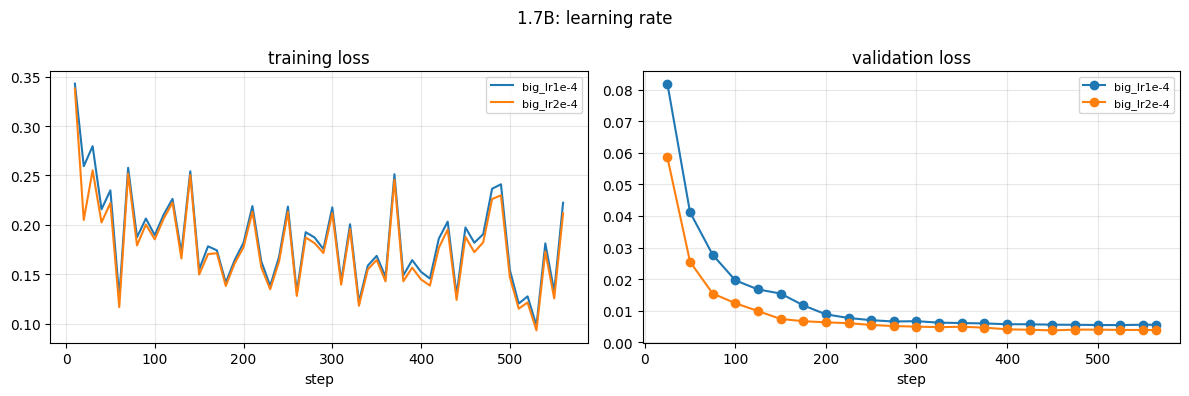

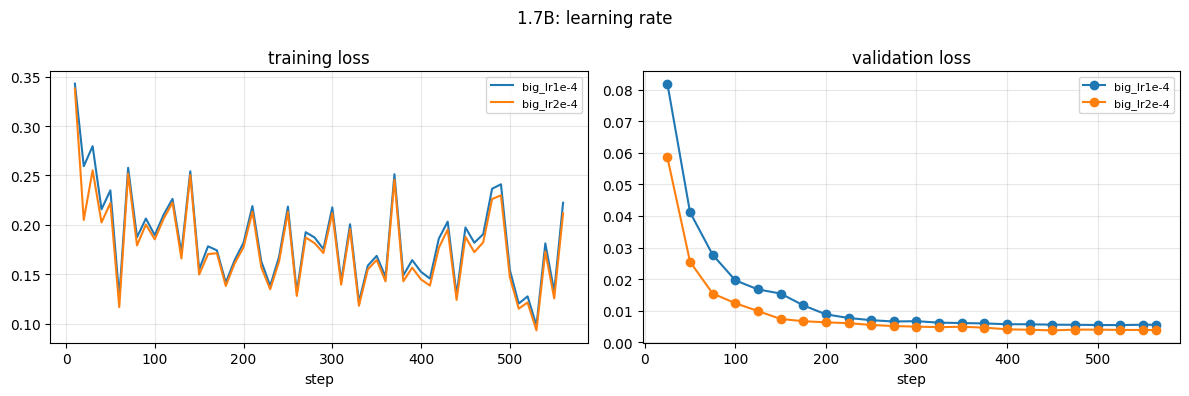

In [30]:
TIE_POINTS = 2.0
LRS = {"big_lr1e-4": 1e-4, "big_lr2e-4": 2e-4}
VAL, META = {}, {}
for name, lr in LRS.items():
    path, cfg = sprint.make_config(name, sprint.deep_merge(HP, {"training": {"lr": lr}}))
    META[name] = sprint.train(name, path, cfg)          # skipped if the adapter is already on Drive
    predict(name, "val", adapter=f"runs/{name}")
    VAL[name] = sprint.score(name, "val", vs="base_1p7b")
    sprint.log_result(name, "val", VAL[name], sprint.settings(cfg), notes="1.7B")
sprint.plot_losses(list(LRS), title="1.7B: learning rate", save_as="loss_1p7b.png")

In [31]:
# ---- Phase 4 checks and the frozen choice
em = {n: VAL[n]["metrics"]["exact_match"] for n in LRS}
check("4.1", all(META[n].get("backend") == "soup" for n in LRS),
      "; ".join(f"{n}: {em[n]}% CI95={VAL[n]['metrics']['exact_match_ci95']} ({META[n].get('backend')})" for n in LRS))
check("4.2", all(VAL[n]["paired_a_minus_b"]["ci95"][0] > 0 for n in LRS),
      "; ".join(f"{n} vs base: {VAL[n]['paired_a_minus_b']['exact_match_diff']:+} {VAL[n]['paired_a_minus_b']['ci95']}" for n in LRS))
curves = {}
for n in LRS:
    va = [l for _, l in sprint.loss_history(f"runs/{n}")["eval"]]
    curves[n] = f"val loss min {min(va):.4f}, last {va[-1]:.4f}" if va else "no val loss"
check("4.3", None, "; ".join(f"{n}: {c}" for n, c in curves.items()))

if os.path.exists("reports/test_lock.json"):
    frozen = json.load(open("reports/best_run.json"))
    print("already frozen:", frozen)
else:
    a, b = em["big_lr1e-4"], em["big_lr2e-4"]
    best = "big_lr1e-4" if (a >= b or b - a < TIE_POINTS) else "big_lr2e-4"
    frozen = {"run": best, "lr": LRS[best], "val_exact_match": em[best], "val_all": em,
              "frozen_at": time.strftime("%Y-%m-%d %H:%M:%S")}
    json.dump(frozen, open("reports/best_run.json", "w"), indent=2)
    print("frozen:", frozen)
BEST_1P7B = frozen["run"]
check("4.4", os.path.exists("reports/best_run.json"), f"BEST_1P7B={BEST_1P7B} frozen at {frozen['frozen_at']}")

✅ PASS   4.1   big_lr1e-4: 87.67% CI95=[84.0, 91.0] (soup); big_lr2e-4: 89.0% CI95=[85.33, 92.33] (soup)
✅ PASS   4.2   big_lr1e-4 vs base: +86.0 [82.0, 89.67]; big_lr2e-4 vs base: +87.33 [83.33, 91.0]
👀 REVIEW 4.3   big_lr1e-4: val loss min 0.0054, last 0.0055; big_lr2e-4: val loss min 0.0037, last 0.0038
already frozen: {'run': 'big_lr1e-4', 'lr': 0.0001, 'val_exact_match': 87.67, 'val_all': {'big_lr1e-4': 87.67, 'big_lr2e-4': 89.0}, 'frozen_at': '2026-11-11 19:14:10'}
✅ PASS   4.4   BEST_1P7B=big_lr1e-4 frozen at 2026-11-11 19:14:10


True

## Phase 5 — Test and stress, once (≈ 5 min)

**Acceptance checks, set before seeing any results:**

| # | Check | Pass when |
|---|---|---|
| 5.1 | Task win | test: 1.7B tuned beats the untouched 1.7B by ≥ 10 points, paired CI95 above 0 |
| 5.2 | Format | parse_strict ≥ 95% on test and stress |
| 5.3 | Size effect, clean | 👀 test: 1.7B − `ep_3` (paired). CI95 above 0 = the bigger model is better; including 0 = no evidence |
| 5.4 | Size effect, stress | 👀 stress: 1.7B − `ep_3` (paired), overall and per group (noise_only / new_wording / both) |
| 5.5 | Gap | 1.7B: test − stress ≤ 15 points |
| 5.6 | Honest process | test/stress run once, after `BEST_1P7B` was frozen |
| 5.7 | Cost | 👀 seconds per 300 rows and adapter size, 1.7B vs 360M |

Expected: new_wording ("rm B", "1830h", "tmrw") is where a bigger model should help most, since it knows more
English from pretraining. If 5.3 and 5.4 both include 0, the 360M is the better choice: same accuracy, about 4.7× cheaper.

In [32]:
frozen = json.load(open("reports/best_run.json"))
BEST_1P7B = frozen["run"]
lock_path = "reports/test_lock.json"
if not os.path.exists(lock_path):
    json.dump({"run": BEST_1P7B, "first_test_at": time.strftime("%Y-%m-%d %H:%M:%S"),
               "best_frozen_at": frozen["frozen_at"]}, open(lock_path, "w"), indent=2)
lock = json.load(open(lock_path))
print("lock:", lock)

final, vs_small = {}, {}
for split in ["test", "stress"]:
    predict("base_1p7b", split)
    predict(BEST_1P7B, split, adapter=f"runs/{BEST_1P7B}")
    if COMPARE:
        vs_small[split] = sprint.score(BEST_1P7B, split, vs="ep3_360m")
        sprint.log_result("FINAL 1.7B vs ep_3 (360M)", split, vs_small[split], notes=f"{BEST_1P7B}; paired vs run 1's ep_3 (360M)")
    final[split] = sprint.score(BEST_1P7B, split, vs="base_1p7b")          # saved report = vs the 1.7B base
    sprint.log_result("FINAL 1.7B vs base", split, final[split], notes=f"{BEST_1P7B}; paired vs untouched 1.7B")

lock: {'run': 'big_lr1e-4', 'first_test_at': '2026-11-11 19:14:10', 'best_frozen_at': '2026-11-11 19:14:10'}
skip predict base_1p7b/test: exists
skip predict big_lr1e-4/test: exists
big_lr1e-4/test: exact_match=93.67% CI95=[90.67, 96.33] schema_valid=99.33% parse_strict=100.0% parse_lenient=100.0%
  vs ep3_360m: +10.0 points, CI95=[6.33, 13.67]
  groups: {'intent=book': 91.89, 'intent=reschedule': 94.05, 'intent=cancel': 95.83, 'intent=check': 92.86, 'complete': 91.08, 'missing_field': 96.5}
  top errors: [('date_wrong', 18), ('time_invented', 1), ('needs_clarification_wrong', 1)]
big_lr1e-4/test: exact_match=93.67% CI95=[90.67, 96.33] schema_valid=99.33% parse_strict=100.0% parse_lenient=100.0%
  vs base_1p7b: +91.67 points, CI95=[88.33, 94.67]
  groups: {'intent=book': 91.89, 'intent=reschedule': 94.05, 'intent=cancel': 95.83, 'intent=check': 92.86, 'complete': 91.08, 'missing_field': 96.5}
  top errors: [('date_wrong', 18), ('time_invented', 1), ('needs_clarification_wrong', 1)]
ski

In [33]:
# ---- per-group breakdown (stress)
gold_st = ev.load_jsonl("data/eval/stress.jsonl")
P = {n: ev.load_preds(sprint.pred_path(n, "stress")) for n in [BEST_1P7B] + (["ep3_360m"] if COMPARE else [])}
groups = bd.by_group(gold_st, P[BEST_1P7B], P.get("ep3_360m"))
small_groups = bd.by_group(gold_st, P["ep3_360m"]) if COMPARE else {}
print(f"  {'group':12s} {'n':>4s} {'360M':>8s} {'1.7B':>8s}   diff [CI95]")
for g, r in groups.items():
    p = r.get("paired_a_minus_b")
    print(f"  {g:12s} {r['n']:4d} {small_groups.get(g, {}).get('exact_match', float('nan')):7.1f}% {r['exact_match']:7.1f}%   "
          + (f"{p['exact_match_diff']:+.1f} {p['ci95']}" if p else "—"))
tiers = {n: bd.field_by_tier(gold_st, p) for n, p in P.items()}
print("\nstress field accuracy by wording tier")
for k, v in tiers[BEST_1P7B].items():
    print(f"  {k:18s} n={v['n']:4d}  360M {tiers.get('ep3_360m', {}).get(k, {}).get('accuracy', float('nan')):6.1f}%  1.7B {v['accuracy']:6.1f}%")
json.dump({"stress_groups": groups, "ep3_360m_groups": small_groups, "field_by_tier": tiers},
          open("reports/stress_breakdown.json", "w"), indent=2)

  group           n     360M     1.7B   diff [CI95]
  both           79    31.6%    69.6%   +38.0 [25.32, 50.63]
  new_wording   102    26.5%    72.5%   +46.1 [35.29, 56.86]
  noise_only    119    57.1%    90.8%   +33.6 [25.21, 42.86]

stress field accuracy by wording tier
  date/base          n=  40  360M   85.0%  1.7B   92.5%
  date/extra         n=  28  360M   78.6%  1.7B  100.0%
  date/heldout       n= 137  360M   56.2%  1.7B   72.3%
  resource/base      n=  30  360M   90.0%  1.7B  100.0%
  resource/extra     n=  42  360M   40.5%  1.7B  100.0%
  resource/heldout   n= 120  360M   30.0%  1.7B   85.8%
  time/base          n=  34  360M  100.0%  1.7B  100.0%
  time/extra         n=  30  360M   76.7%  1.7B   90.0%
  time/heldout       n= 128  360M   93.0%  1.7B   99.2%


In [34]:
# ---- 5.7 cost: inference time on the same 300 val rows, and adapter size
def adapter_mb(run_dir):
    d = sprint.find_adapter(run_dir)
    f = os.path.join(d, "adapter_model.safetensors") if d else None
    return round(os.path.getsize(f) / 2**20, 1) if f and os.path.exists(f) else None

predict(BEST_1P7B, "val", adapter=f"runs/{BEST_1P7B}", force=True, out="reports/preds/timing_1p7b_val.pred.jsonl")
if sprint.find_adapter(V1_EP3):
    predict("ep3_360m", "val", adapter=V1_EP3, base=SMALL, force=True, out="reports/preds/timing_360m_val.pred.jsonl")
speed = json.load(open("reports/speed.json"))
t_big = speed.get("timing_1p7b_val.pred.jsonl", {}).get("seconds")
t_small = speed.get("timing_360m_val.pred.jsonl", {}).get("seconds")
COST = {"seconds_300_rows": {"1.7B": t_big, "360M": t_small},
        "adapter_mb": {"1.7B": adapter_mb(f"runs/{BEST_1P7B}"), "360M": adapter_mb(V1_EP3)}}
json.dump(COST, open("reports/cost.json", "w"), indent=2)
print(COST)

$ /usr/bin/python3 scripts/predict.py --base HuggingFaceTB/SmolLM2-1.7B-Instruct --input data/eval/val.jsonl --output reports/preds/timing_1p7b_val.pred.jsonl --batch-size 32 --adapter runs/big_lr1e-4

Loading weights: 100%|██████████| 218/218 [00:00<00:00, 6249.93it/s]
loaded adapter from runs/big_lr1e-4
300 rows in 25.7s on cuda -> reports/preds/timing_1p7b_val.pred.jsonl
$ /usr/bin/python3 scripts/predict.py --base HuggingFaceTB/SmolLM2-360M-Instruct --input data/eval/val.jsonl --output reports/preds/timing_360m_val.pred.jsonl --batch-size 32 --adapter /content/drive/MyDrive/soup-sprint/runs/ep_3

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 5060.38it/s]
loaded adapter from /content/drive/MyDrive/soup-sprint/runs/ep_3
300 rows in 50.7s on cuda -> reports/preds/timing_360m_val.pred.jsonl
{'seconds_300_rows': {'1.7B': 25.7, '360M': 50.7}, 'adapter_mb': {'1.7B': 12.0, '360M': 33.2}}


In [35]:
# ---- Phase 5 checks
t, s = final["test"], final["stress"]
p = t["paired_a_minus_b"]
check("5.1", p["exact_match_diff"] >= 10 and p["ci95"][0] > 0,
      f"test {t['metrics']['exact_match']}% vs untouched 1.7B {t['b']['metrics']['exact_match']}%: {p['exact_match_diff']:+} {p['ci95']}")
check("5.2", t["metrics"]["parse_strict"] >= 95 and s["metrics"]["parse_strict"] >= 95,
      f"parse_strict test {t['metrics']['parse_strict']}%, stress {s['metrics']['parse_strict']}%")
if COMPARE:
    for cid, split in [("5.3", "test"), ("5.4", "stress")]:
        r = vs_small[split]; q = r["paired_a_minus_b"]
        verdict = "1.7B better" if q["ci95"][0] > 0 else ("360M better" if q["ci95"][1] < 0 else "no clear difference")
        extra = ("; by group: " + ", ".join(f"{g} {v['paired_a_minus_b']['exact_match_diff']:+.1f} {v['paired_a_minus_b']['ci95']}"
                                             for g, v in groups.items())) if split == "stress" else ""
        check(cid, None, f"{split}: 1.7B {r['metrics']['exact_match']}% vs 360M {r['b']['metrics']['exact_match']}%: "
                         f"{q['exact_match_diff']:+} {q['ci95']} -> {verdict}{extra}")
gap = t["metrics"]["exact_match"] - s["metrics"]["exact_match"]
check("5.5", gap <= 15, f"1.7B gap test - stress = {gap:.1f} points")
check("5.6", lock["run"] == BEST_1P7B and lock["best_frozen_at"] == frozen["frozen_at"],
      f"test first run at {lock['first_test_at']} with {lock['run']}; frozen at {frozen['frozen_at']}")
c = COST
ratio = f"{c['seconds_300_rows']['1.7B'] / c['seconds_300_rows']['360M']:.1f}× slower" if all(c["seconds_300_rows"].values()) else "n/a"
check("5.7", None, f"300 val rows: 1.7B {c['seconds_300_rows']['1.7B']}s vs 360M {c['seconds_300_rows']['360M']}s ({ratio}); "
                   f"adapter 1.7B {c['adapter_mb']['1.7B']} MB vs 360M {c['adapter_mb']['360M']} MB")
sprint.show_errors(BEST_1P7B, "stress", n=10)

✅ PASS   5.1   test 93.67% vs untouched 1.7B 2.0%: +91.67 [88.33, 94.67]
✅ PASS   5.2   parse_strict test 100.0%, stress 100.0%
👀 REVIEW 5.3   test: 1.7B 93.67% vs 360M 83.67%: +10.0 [6.33, 13.67] -> 1.7B better
👀 REVIEW 5.4   stress: 1.7B 79.0% vs 360M 40.0%: +39.0 [32.67, 45.33] -> 1.7B better; by group: both +38.0 [25.32, 50.63], new_wording +46.1 [35.29, 56.86], noise_only +33.6 [25.21, 42.86]
✅ PASS   5.5   1.7B gap test - stress = 14.7 points
✅ PASS   5.6   test first run at 2026-11-11 19:14:10 with big_lr1e-4; frozen at 2026-11-11 19:14:10
👀 REVIEW 5.7   300 val rows: 1.7B 25.7s vs 360M 50.7s (0.5× slower); adapter 1.7B 12.0 MB vs 360M 33.2 MB
63 failed rows in /content/drive/MyDrive/soup-sprint-1p7b/reports/big_lr1e-4_stress.errors.jsonl; showing 10
- [date_wrong] today=2026-04-29 | tell me whether anything is free in court1 tmrw.
    gold: {"intent": "check", "date": "2026-04-30", "time": null, "resource": "Court 1", "needs_clarification": false}
    got : '{"intent": "check",

## Phase 6 — General skills: IFEval and HellaSwag (≈ 60–90 min) — the main goal

Run 1's 360M scored IFEval 33.1 → 31.6 and HellaSwag 56.7 → 57.0 (untouched → tuned). Those are copied from
run 1's folder; this phase measures the untouched and the tuned 1.7B with the **same tasks, metrics and settings**.

**What to expect:** these benchmarks measure what the model learned in **pretraining and general instruction
tuning**. Fine-tuning on booking JSON does not teach them, so the tuned 1.7B should score close to the untouched
1.7B. Any gain over the 360M comes from the bigger base model, not from our fine-tuning. The useful result is
the pair "1.7B is better at general skills **and** still keeps them after our fine-tuning".

| # | Check | Pass when |
|---|---|---|
| 6.1 | Gain over the 360M | tuned 1.7B beats run 1's tuned 360M (`ep_3`) on IFEval **and** HellaSwag, each by more than 1.96 × the combined standard error |
| 6.2 | No forgetting | tuned 1.7B drops ≤ 5 points from the untouched 1.7B on each |
| 6.3 | Where the gain comes from | 👀 base-vs-base (pretraining) and tuned-vs-base (our fine-tuning), for both sizes |

In [36]:
RUN_LM_EVAL = True   # the main result of this notebook; set False only to skip it for now
if RUN_LM_EVAL:
    !pip -q install "lm-eval[ifeval]"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [37]:
import glob, math
TASKS = {"ifeval": ("prompt_level_strict_acc,none", True), "hellaswag": ("acc_norm,none", False)}

def lm_eval(tag, base=BIG, adapter_dir=None, copy_from=None):
    """{task: (score %, stderr %)}. copy_from: an earlier run's reports/lm_eval/<tag> prefix to reuse."""
    scores = {}
    for task, (metric, chat) in TASKS.items():
        out = f"reports/lm_eval/{tag}_{task}"
        if copy_from and not glob.glob(f"{out}/**/results_*.json", recursive=True) and os.path.isdir(f"{copy_from}_{task}"):
            shutil.copytree(f"{copy_from}_{task}", out, dirs_exist_ok=True); print("copied", f"{copy_from}_{task}")
        if not glob.glob(f"{out}/**/results_*.json", recursive=True):
            if copy_from:
                return None                       # run 1 results not found: nothing to compare with
            args = f"pretrained={base},dtype=bfloat16" + (f",peft={adapter_dir}" if adapter_dir else "")
            cmd = [sys.executable, "-m", "lm_eval", "--model", "hf", "--model_args", args, "--tasks", task,
                   "--batch_size", "auto", "--output_path", out, "--seed", "0"]
            if chat:
                cmd.append("--apply_chat_template")
            sprint.sh(cmd, log=f"logs/lm_eval_{tag}_{task}.log", quiet=True)
        res = json.load(open(sorted(glob.glob(f"{out}/**/results_*.json", recursive=True))[-1]))["results"][task]
        se = res.get(metric.replace(",", "_stderr,"))
        scores[task] = (round(100 * res[metric], 2), round(100 * se, 2) if isinstance(se, (int, float)) else None)
    return scores

if RUN_LM_EVAL:
    LM = {
        "360M untouched": lm_eval("v1_base_360m", copy_from=os.path.join(V1_PROJECT, "reports/lm_eval/base")),
        "360M tuned (ep_3)": lm_eval("v1_ep3_360m", copy_from=os.path.join(V1_PROJECT, "reports/lm_eval/best")),
        "1.7B untouched": lm_eval("base_1p7b"),
        "1.7B tuned": lm_eval("best_1p7b", adapter_dir=sprint.find_adapter(f"runs/{BEST_1P7B}")),
    }
    json.dump(LM, open("reports/lm_eval_summary.json", "w"), indent=2)
    print(f"{'model':20s} " + "  ".join(f"{t:>16s}" for t in TASKS))
    for m, sc in LM.items():
        print(f"{m:20s} " + ("  ".join(f"{sc[t][0]:8.2f} ± {sc[t][1] or float('nan'):5.2f}" for t in TASKS) if sc else "not available"))

$ /usr/bin/python3 -m lm_eval --model hf --model_args pretrained=HuggingFaceTB/SmolLM2-1.7B-Instruct,dtype=bfloat16 --tasks ifeval --batch_size auto --output_path reports/lm_eval/base_1p7b_ifeval --seed 0 --apply_chat_template
$ /usr/bin/python3 -m lm_eval --model hf --model_args pretrained=HuggingFaceTB/SmolLM2-1.7B-Instruct,dtype=bfloat16 --tasks hellaswag --batch_size auto --output_path reports/lm_eval/base_1p7b_hellaswag --seed 0
$ /usr/bin/python3 -m lm_eval --model hf --model_args pretrained=HuggingFaceTB/SmolLM2-1.7B-Instruct,dtype=bfloat16,peft=runs/big_lr1e-4 --tasks ifeval --batch_size auto --output_path reports/lm_eval/best_1p7b_ifeval --seed 0 --apply_chat_template
$ /usr/bin/python3 -m lm_eval --model hf --model_args pretrained=HuggingFaceTB/SmolLM2-1.7B-Instruct,dtype=bfloat16,peft=runs/big_lr1e-4 --tasks hellaswag --batch_size auto --output_path reports/lm_eval/best_1p7b_hellaswag --seed 0
model                          ifeval         hellaswag
360M untouched          33

In [38]:
# ---- Phase 6 checks
def z(a, b):
    """(difference, z) for two independent scores with standard errors."""
    (sa, ea), (sb, eb) = a, b
    se = math.sqrt((ea or 0) ** 2 + (eb or 0) ** 2)
    return round(sa - sb, 2), (round((sa - sb) / se, 2) if se else None)

if RUN_LM_EVAL:
    big, big0, small, small0 = LM["1.7B tuned"], LM["1.7B untouched"], LM["360M tuned (ep_3)"], LM["360M untouched"]
    if small:
        gains = {t: z(big[t], small[t]) for t in TASKS}
        check("6.1", all(d > 0 and zz is not None and zz > 1.96 for d, zz in gains.values()),
              "tuned 1.7B - tuned 360M: " + ", ".join(f"{t} {big[t][0]} vs {small[t][0]} ({d:+}, z={zz})" for t, (d, zz) in gains.items()))
    else:
        check("6.1", None, "run 1's lm-eval results not found in " + V1_PROJECT + "; compare by hand with IFEval 31.61, HellaSwag 57.04")
    drops = {t: round(big0[t][0] - big[t][0], 2) for t in TASKS}
    check("6.2", all(d <= 5 for d in drops.values()),
          "drop (untouched - tuned 1.7B): " + ", ".join(f"{t} {big0[t][0]} -> {big[t][0]} ({-d:+})" for t, d in drops.items()))
    parts = [f"{t}: pretraining (1.7B vs 360M untouched) {z(big0[t], small0[t])[0] if small0 else 'n/a':+}, "
             f"our fine-tuning (1.7B tuned vs untouched) {z(big[t], big0[t])[0]:+}" for t in TASKS]
    check("6.3", None, "; ".join(parts))

✅ PASS   6.1   tuned 1.7B - tuned 360M: ifeval 48.98 vs 31.61 (+17.37, z=5.92), hellaswag 71.53 vs 57.04 (+14.49, z=21.78)
✅ PASS   6.2   drop (untouched - tuned 1.7B): ifeval 47.13 -> 48.98 (+1.85), hellaswag 71.72 -> 71.53 (-0.19)
👀 REVIEW 6.3   ifeval: pretraining (1.7B vs 360M untouched) +14.04, our fine-tuning (1.7B tuned vs untouched) +1.85; hellaswag: pretraining (1.7B vs 360M untouched) +14.98, our fine-tuning (1.7B tuned vs untouched) -0.19


### Results summary

In [39]:
lm = json.load(open("reports/lm_eval_summary.json")) if os.path.exists("reports/lm_eval_summary.json") else None
bdj = json.load(open("reports/stress_breakdown.json"))
cost = json.load(open("reports/cost.json"))
lines = ["# Results — SmolLM2-1.7B vs 360M on the v2 data", "",
         f"BEST_1P7B: `{BEST_1P7B}` (lr {frozen['lr']}, chosen on val: {frozen['val_all']}); Soup; 3 epochs, LoRA r16, seed 42.", "",
         sprint.table("results_log").to_markdown(index=False), "",
         "## Stress by group", "", "| group | n | 360M | 1.7B | diff (1.7B − 360M) | CI95 |", "|---|---|---|---|---|---|"]
for g, r in bdj["stress_groups"].items():
    q = r.get("paired_a_minus_b")
    small = bdj["ep3_360m_groups"].get(g, {}).get("exact_match", "—")
    lines.append(f"| {g} | {r['n']} | {small} | {r['exact_match']} | {q['exact_match_diff'] if q else '—'} | {q['ci95'] if q else '—'} |")
lines += ["", "## Cost", "", "| | 360M | 1.7B |", "|---|---|---|",
          f"| seconds per 300 rows | {cost['seconds_300_rows']['360M']} | {cost['seconds_300_rows']['1.7B']} |",
          f"| adapter size (MB) | {cost['adapter_mb']['360M']} | {cost['adapter_mb']['1.7B']} |"]
if lm:
    lines += ["", "## General skills (lm-eval; score ± standard error)", "",
              "| model | " + " | ".join(TASKS) + " |", "|---|" + "---|" * len(TASKS)]
    lines += [f"| {m} | " + " | ".join(f"{sc[t][0]} ± {sc[t][1]}" for t in TASKS) + " |" for m, sc in lm.items() if sc]
open("reports/RESULTS_1p7b.md", "w", encoding="utf-8").write("\n".join(lines))
print("\n".join(lines))
print()
sprint.checks_summary()

# Results — SmolLM2-1.7B vs 360M on the v2 data

BEST_1P7B: `big_lr1e-4` (lr 0.0001, chosen on val: {'big_lr1e-4': 87.67, 'big_lr2e-4': 89.0}); Soup; 3 epochs, LoRA r16, seed 42.

| run                       | split   | lr     | epochs   | rank   | seed   |   exact_match | ci95           |   schema_valid |   parse_strict | notes                                     | paired_diff                        |
|:--------------------------|:--------|:-------|:---------|:-------|:-------|--------------:|:---------------|---------------:|---------------:|:------------------------------------------|:-----------------------------------|
| base_1p7b                 | val     | —      | —        | —      | —      |          1.67 | [0.33, 3.33]   |          98.67 |            100 | untouched SmolLM2-1.7B-Instruct           | nan                                |
| big_lr1e-4                | val     | 0.0001 | 3        | 16     | 42     |         87.67 | [84.0, 91.0]   |          98.67 |            100

**Done → Runtime → Disconnect and delete runtime** to stop using compute units.
Everything is in `MyDrive/soup-sprint-1p7b/`. The tuned adapter is `runs/<BEST_1P7B>/`.